# 스프린트 미션4 | 은행 마케팅 데이터 분석 #

### 목차 ###

0. 서론 
1. 데이터 탐색 
2. 데이터 전처리
3. 모델 학습 및 최적화
4. 평가 및 최종 제출

## 0. 서론 ##

 포르투갈 은행의 마케팅 데이터를 분석한다.
 결정트리와 앙상블 기법을 사용하여 분류 모델을 구축하고, 마케팅 캠페인의 효율성을 높이는 전략을 도출한다.

 -> 데이터는 2008년부터 2010년까지의 은행 마케팅 캠페인 데이터를 포함하고 있다. 
 
 목표는 데이터를 통해 고객이 정기 예금을 가입할 가능성을 예측하고, 이를 통해 마케팅 캠페인의 효율성을 높이는 것이다. 
 
 정기 예금과 관련 있는 요소들을 파악하고, 고객의 행동을 이해한 후 어떤 상황에서 어떤 고객이 정기 예금을 가입할지 분석한다.



## 1. 데이터 확인 ##

### 1) 데이터 불러오기 ###

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import SMOTE
from imblearn.combine import SMOTETomek
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.linear_model import LogisticRegression



bank_df = pd.read_csv("bank-additional-full.csv", sep = ";")
bank_df

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes


### 2) 데이터 구조 파악하기 ###

In [34]:
bank_df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [35]:
bank_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [36]:
bank_df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [37]:
bank_df.dtypes

age                 int64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome           object
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                  object
dtype: object

## 2. 데이터 전처리 ##

### 1) 결측값 ###


In [38]:
bank_df.isna().sum()

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

### 2) 중복값 ###

In [39]:
bank_df.duplicated().sum()

np.int64(12)

확인된 중복값 : 12개

중복값 내용 확인 후 제거 진행

In [40]:
# 중복 내용 찾아보기
dup_mask = bank_df.duplicated(keep=False)  # 중복되는 모든 행 True
dup_rows = bank_df.loc[dup_mask].copy()

print("중복에 해당하는 행 개수(중복 포함):", dup_rows.shape[0])
display(dup_rows.head(24))


중복에 해당하는 행 개수(중복 포함): 24


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
1265,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
1266,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
12260,36,retired,married,unknown,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
12261,36,retired,married,unknown,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
14155,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
16819,47,technician,divorced,high.school,no,yes,no,cellular,jul,thu,...,3,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
16956,47,technician,divorced,high.school,no,yes,no,cellular,jul,thu,...,3,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
18464,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
18465,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no


In [41]:
# 특성(피처)만 동일한데 y가 다른 경우가 있는지 체크
target_col = "y"
feature_cols = [c for c in bank_df.columns if c != target_col]

# 피처 기준 중복 그룹에서 y 종류가 2개 이상이면 "라벨 충돌"
conflict_groups = (
    bank_df[bank_df.duplicated(subset=feature_cols, keep=False)]
    .groupby(feature_cols)[target_col]
    .nunique()
)

num_conflicts = (conflict_groups > 1).sum()
print("피처는 같은데 y가 다른(라벨 충돌) 그룹 수:", int(num_conflicts))


피처는 같은데 y가 다른(라벨 충돌) 그룹 수: 0


In [42]:
before_shape = bank_df.shape
before_dups = bank_df.duplicated().sum()

bank_df = bank_df.drop_duplicates().reset_index(drop=True)

after_shape = bank_df.shape
after_dups = bank_df.duplicated().sum()

print("제거 전 shape:", before_shape, "| 중복 개수:", int(before_dups))
print("제거 후 shape:", after_shape,  "| 중복 개수:", int(after_dups))
print("총 제거된 행 수:", before_shape[0] - after_shape[0])


제거 전 shape: (41188, 21) | 중복 개수: 12
제거 후 shape: (41176, 21) | 중복 개수: 0
총 제거된 행 수: 12


중복값 12개 제거

### 3) 이상치 ###

In [43]:
# 1) 수치형 컬럼 지정 (원하는 컬럼만 쓰고 싶으면 네 방식대로 직접 리스트 만들어도 OK)
num_cols = bank_df.select_dtypes(include=[np.number]).columns.tolist()

# 2) 기본 통계로 범위 먼저 확인
display(bank_df[num_cols].describe().T)

# 3) iqr(사분위수) 기준 이상치 개수/비율 요약
q1 = bank_df[num_cols].quantile(0.25)
q3 = bank_df[num_cols].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outlier_mask = (bank_df[num_cols] < lower) | (bank_df[num_cols] > upper)

outlier_summary = pd.DataFrame({
    "outlier_count": outlier_mask.sum(),
    "outlier_ratio(%)": (outlier_mask.mean() * 100).round(2),
    "min": bank_df[num_cols].min(),
    "max": bank_df[num_cols].max(),
    "lower_bound": lower,
    "upper_bound": upper
}).sort_values("outlier_count", ascending=False)

display(outlier_summary)

,count,mean,std,min,25%,50%,75%,max
age,41176.0,40.023800,10.420680,17.000,32.000,38.000,47.000,98.000
duration,41176.0,258.315815,259.305321,0.000,102.000,180.000,319.000,4918.000
campaign,41176.0,2.567879,2.770318,1.000,1.000,2.000,3.000,56.000
pdays,41176.0,962.464810,186.937102,0.000,999.000,999.000,999.000,999.000
previous,41176.0,0.173013,0.494964,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41176.0,0.081922,1.570883,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41176.0,93.575720,0.578839,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41176.0,-40.502863,4.627860,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41176.0,3.621293,1.734437,0.634,1.344,4.857,4.961,5.045
nr.employed,41176.0,5167.034870,72.251364,4963.600,5099.100,5191.000,5228.100,5228.100


,outlier_count,outlier_ratio(%),min,max,lower_bound,upper_bound
previous,5625,13.66,0.000,7.000,0.0000,0.0000
duration,2963,7.20,0.000,4918.000,-223.5000,644.5000
campaign,2406,5.84,1.000,56.000,-2.0000,6.0000
pdays,1515,3.68,0.000,999.000,999.0000,999.0000
age,468,1.14,17.000,98.000,9.5000,69.5000
cons.conf.idx,446,1.08,-50.800,-26.900,-52.1500,-26.9500
emp.var.rate,0,0.00,-3.400,1.400,-6.6000,6.2000
cons.price.idx,0,0.00,92.201,94.767,91.6965,95.3725
euribor3m,0,0.00,0.634,5.045,-4.0815,10.3865
nr.employed,0,0.00,4963.600,5228.100,4905.6000,5421.6000


1. 'previous'값의 최소값이 0으로 잡힘
    -> 대부분 0이 아닌 1~7의 값들이 이상치로 처리된것으로 보임. 오류는 아닌것 같으니 일단 유지

2. 'pday' upper_bound가 999로 고정되어 있음
    -> 999는 이전에 연락한적 없다는 의미로 해석 -> 후에 값을 변환해서 사용

3. 'duration', 'champion'의 최댓값이 극단적으로 크게 잡힘
    -> 오류값인지 정상적인 극단값인지 분포&상위값을 확인하기로 함


### 4) 목표변수 불균형 확인 ###

In [44]:
# 보기 이쁘게 가공
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4)

# 수치형 / 범주형 컬럼 자동 분리
num_cols = bank_df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = bank_df.select_dtypes(exclude=[np.number]).columns.tolist()

print("num_cols:", num_cols)
print("cat_cols:", cat_cols)

num_cols: ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
cat_cols: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'y']


#### 4-1) 수치형 분포: 히스토그램

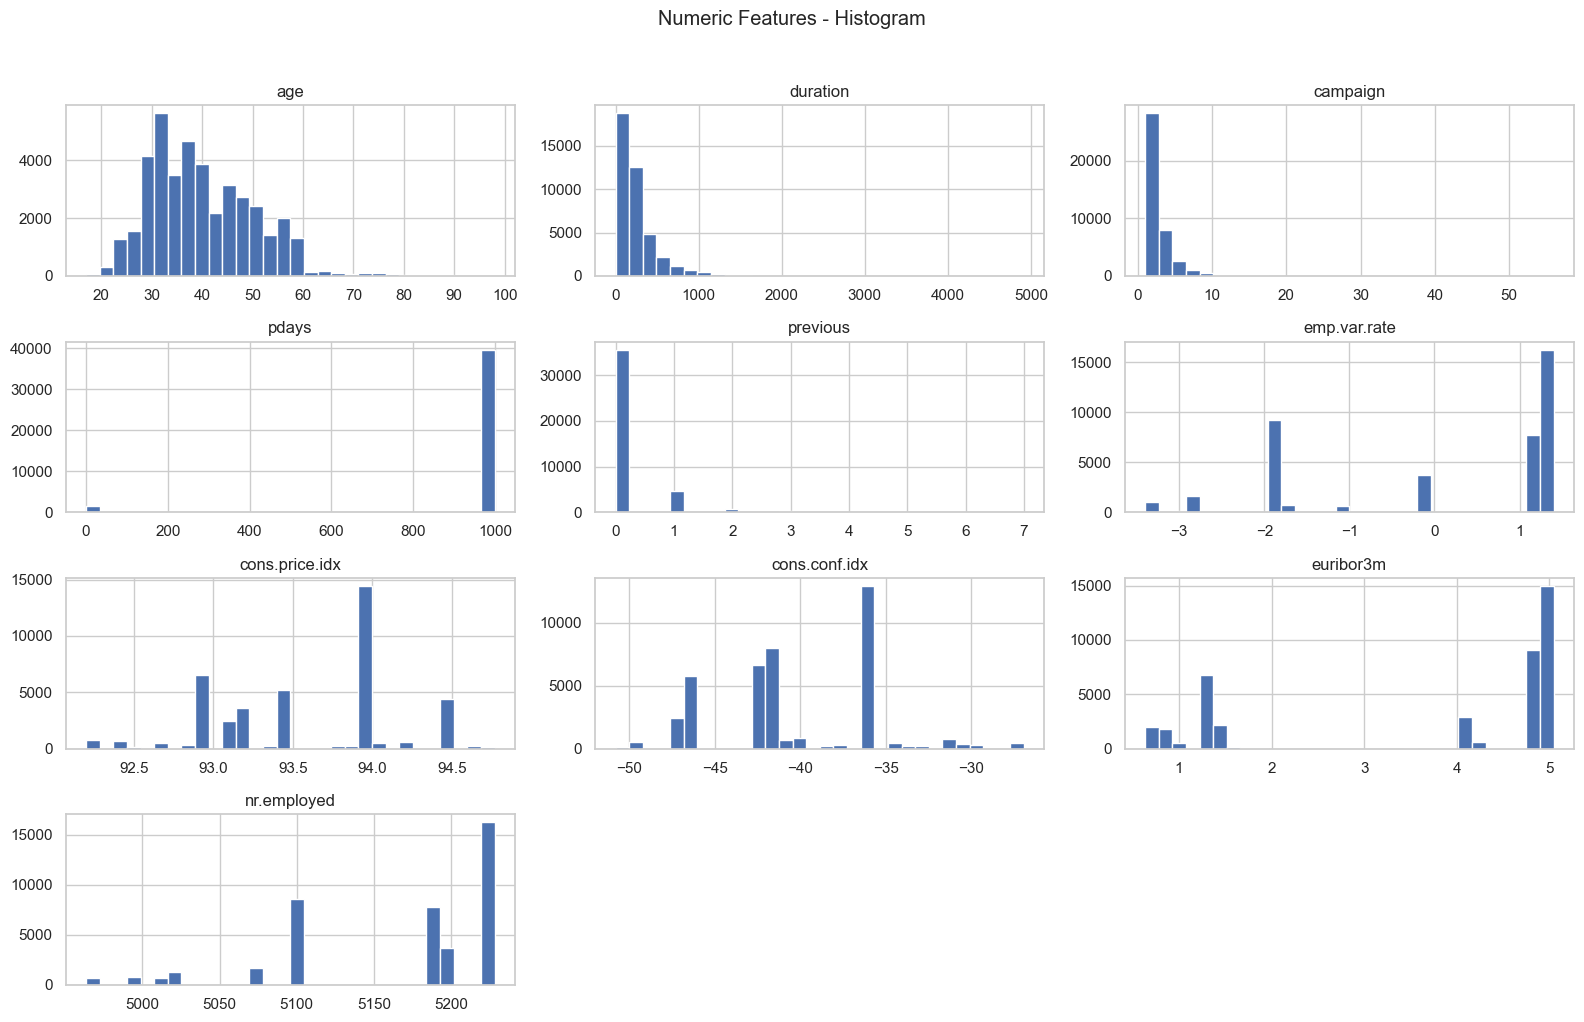

In [45]:
bank_df[num_cols].hist(bins=30, figsize=(16, 10))
plt.suptitle("Numeric Features - Histogram", y=1.02)
plt.tight_layout()
plt.show()


#### 4-2) 수치형 이상치 확인: 컬럼별 박스플롯

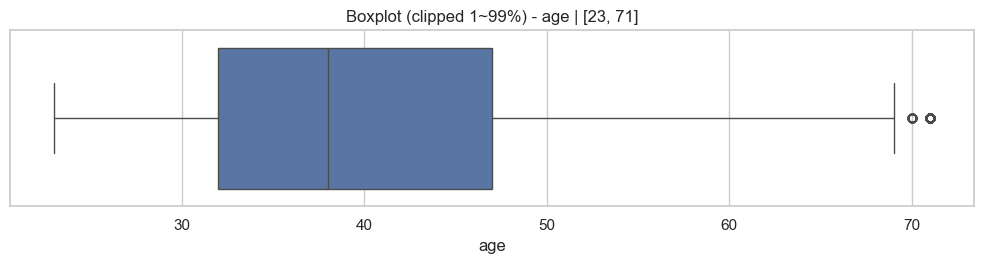

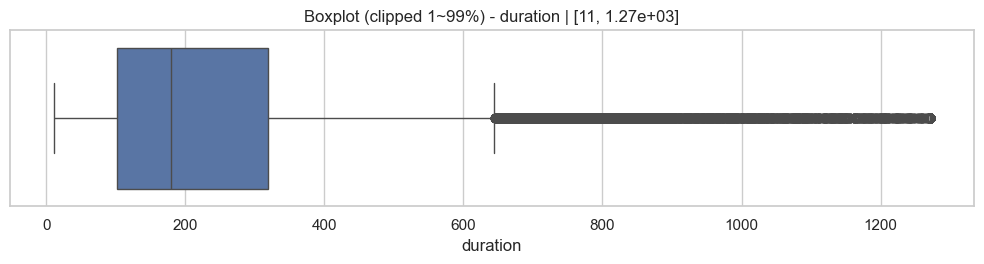

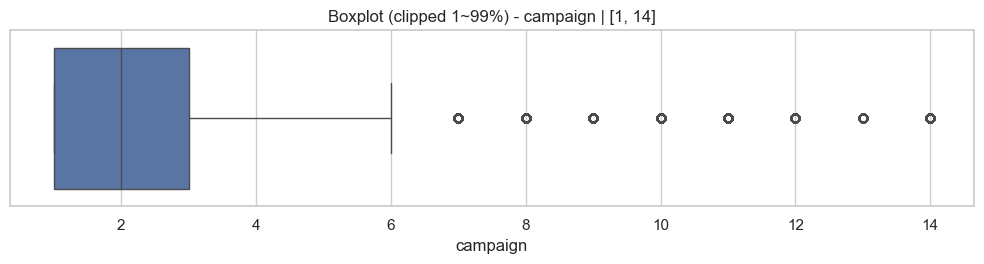

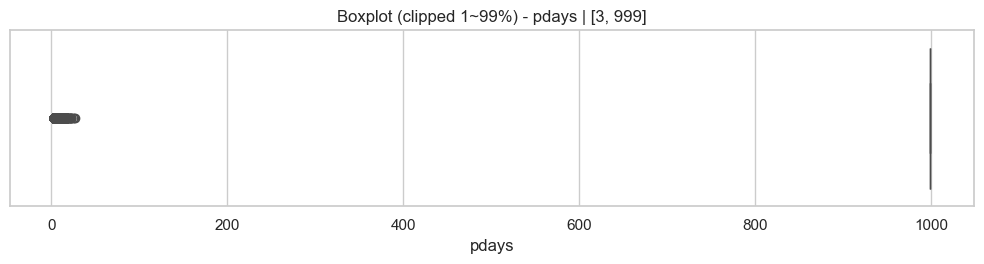

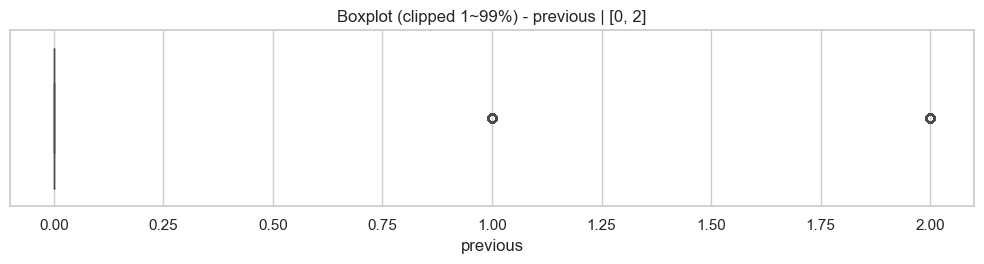

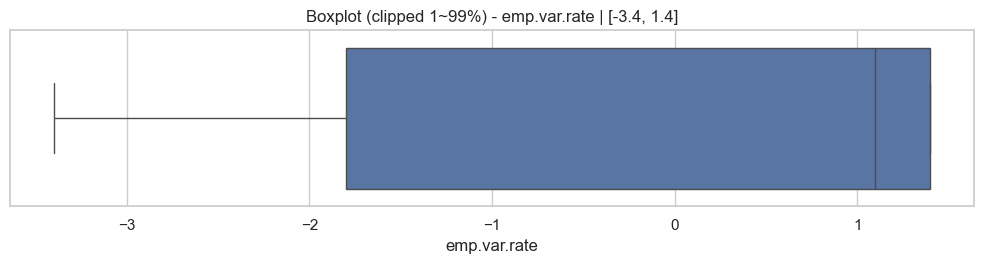

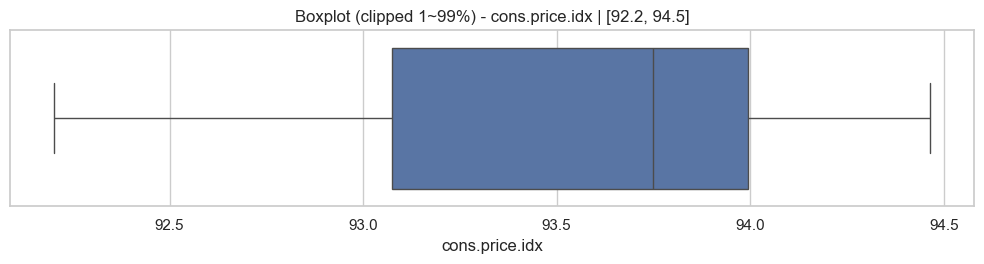

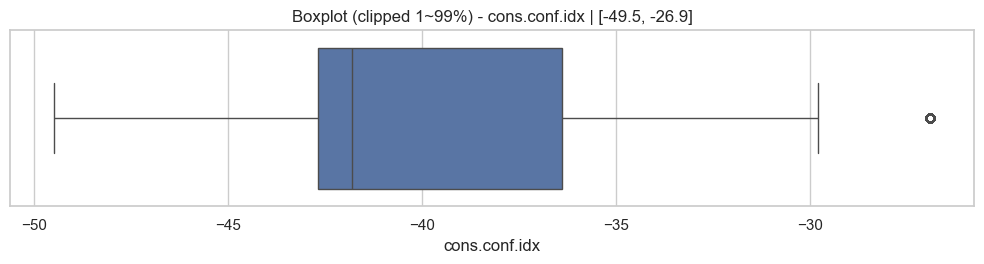

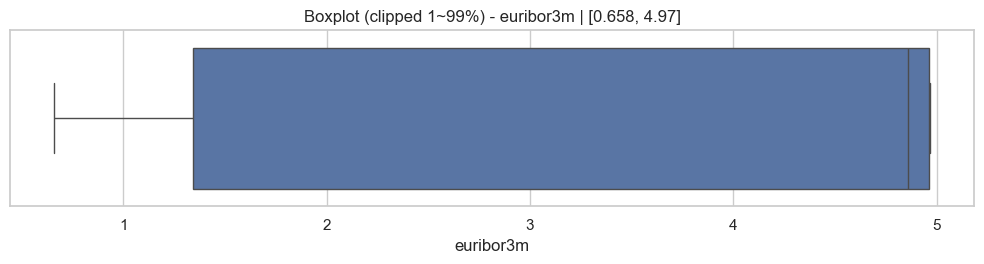

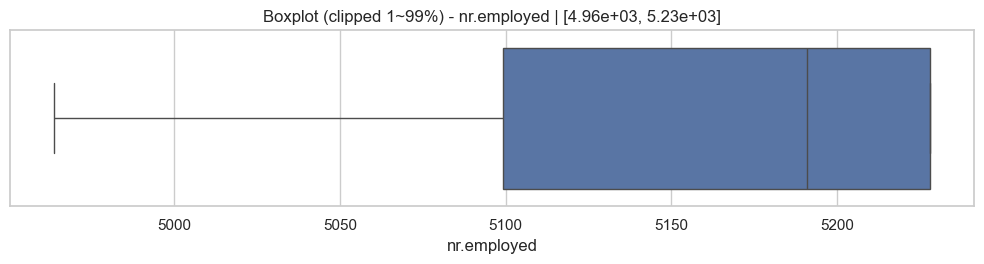

In [46]:
# for col in num_cols:
#     plt.figure(figsize=(10, 2.5))
#     sns.boxplot(x=bank_df[col])
#     plt.title(f"Boxplot - {col}")
#     plt.tight_layout()
#     plt.show()

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 수치형 컬럼 자동 선택
num_cols = bank_df.select_dtypes(include=[np.number]).columns.tolist()

# 시각화용 클리핑 범위(원하면 0.01, 0.99만 조정)
LOW_Q, HIGH_Q = 0.01, 0.99

for col in num_cols:
    s = bank_df[col]
    lo, hi = s.quantile(LOW_Q), s.quantile(HIGH_Q)

    # ✅ 원본은 건드리지 않고, 시각화용으로만 클리핑
    s_clip = s.clip(lower=lo, upper=hi)

    plt.figure(figsize=(10, 2.8))
    sns.boxplot(x=s_clip)  # 필요하면 showfliers=False 도 가능
    plt.title(f"Boxplot (clipped {int(LOW_Q*100)}~{int(HIGH_Q*100)}%) - {col} | [{lo:.3g}, {hi:.3g}]")
    plt.tight_layout()
    plt.show()


#### 4-3) 범주형 분포: 카운트플롯(컬럼별)

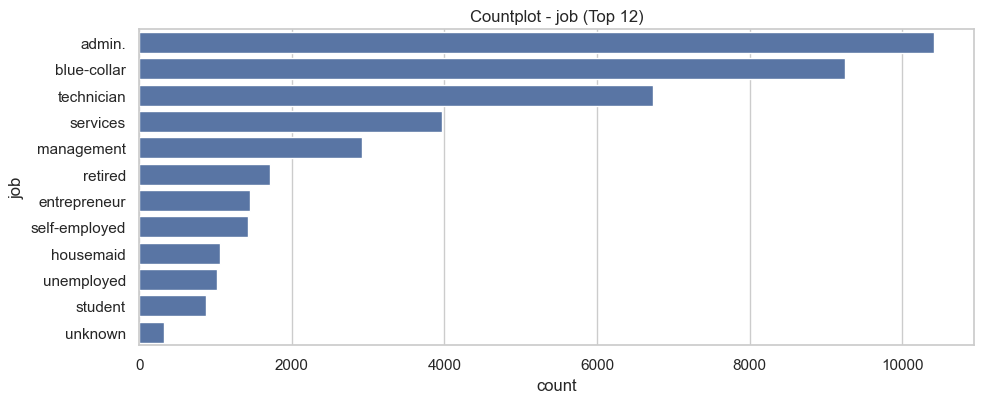

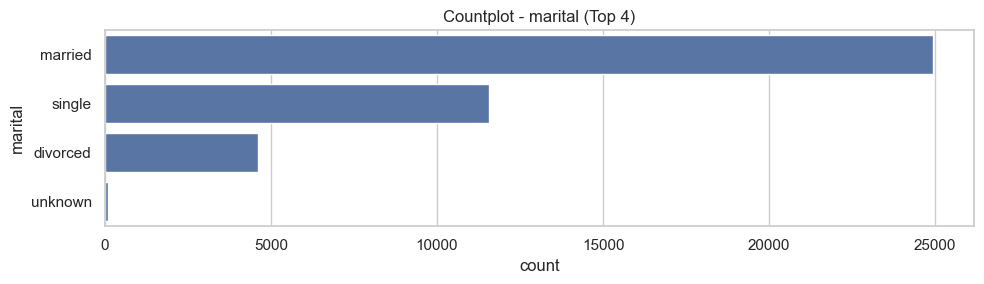

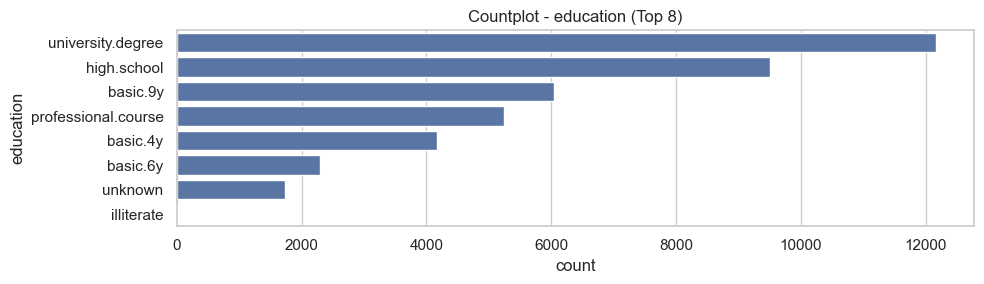

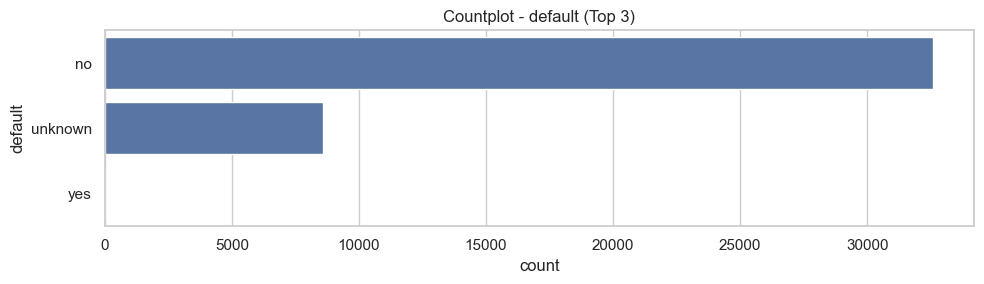

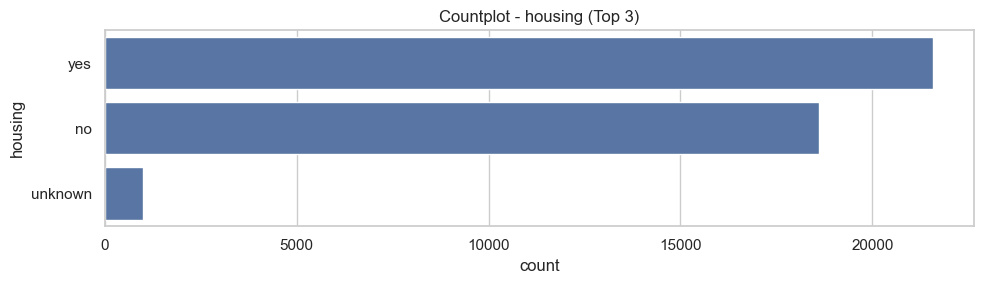

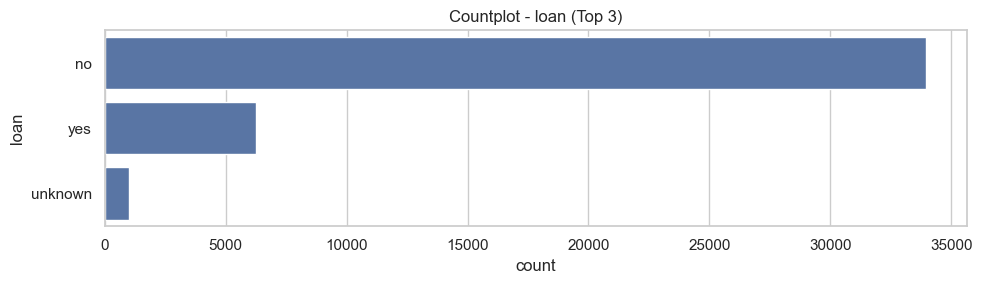

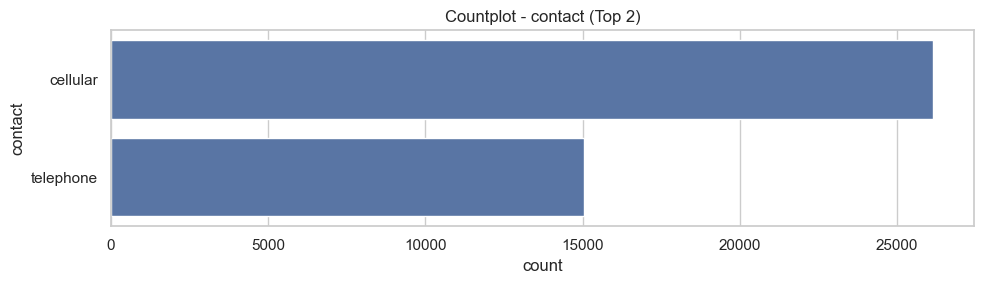

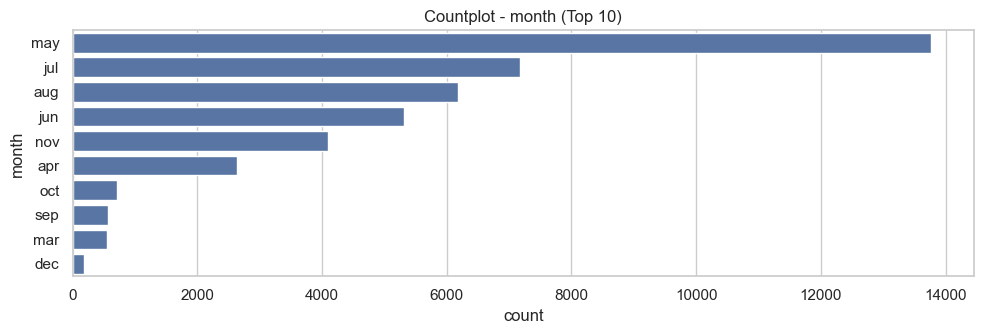

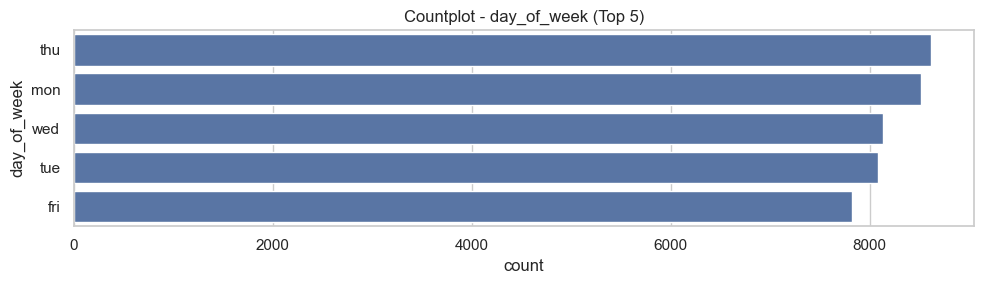

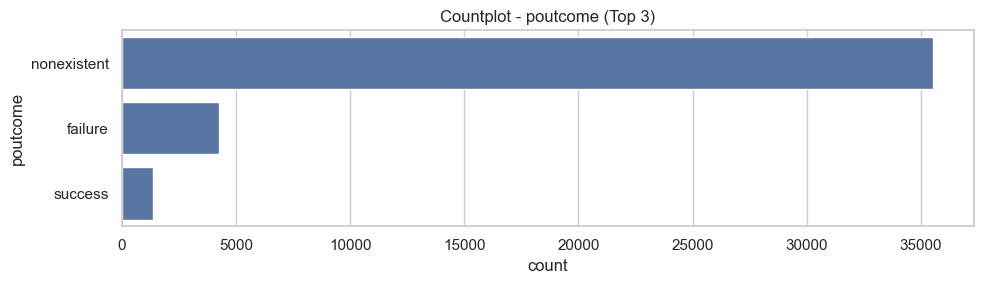

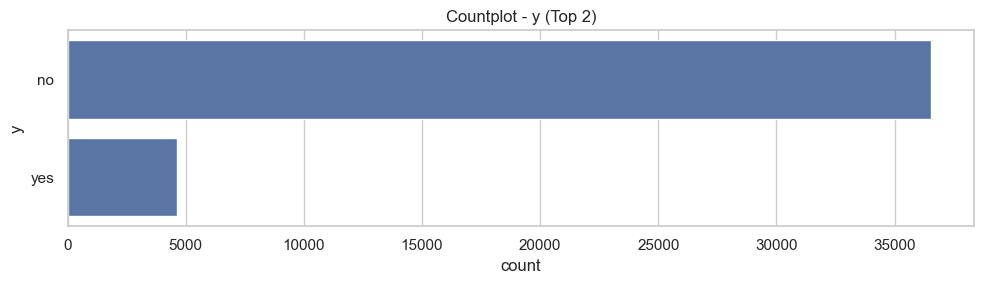

In [47]:
TOP_N = 20

for col in cat_cols:
    vc = bank_df[col].value_counts(dropna=False)
    order = vc.index[:TOP_N]

    plt.figure(figsize=(10, max(3, len(order) * 0.35)))
    sns.countplot(data=bank_df, y=col, order=order)
    plt.title(f"Countplot - {col} (Top {min(TOP_N, len(vc))})")
    plt.tight_layout()
    plt.show()

    

#### 4-4) 스택 히스토그램
    -> 데이터를 히스토그램으로 시각화하고, 그 중 보험 가입 여부를 yes/no로 구분한다.

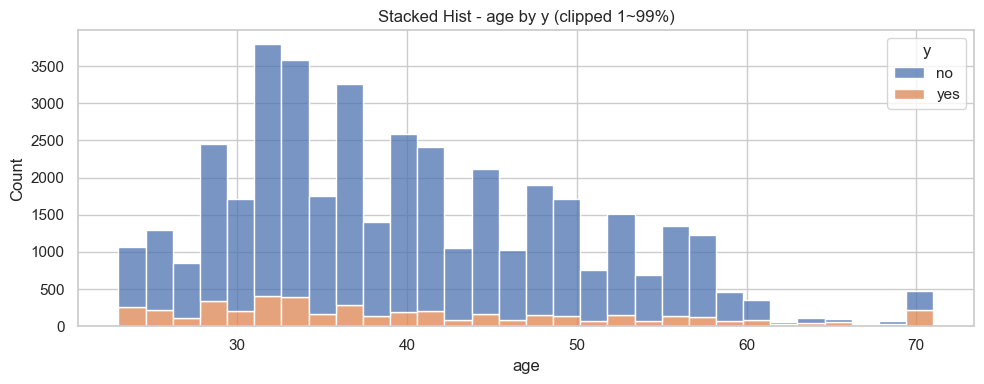

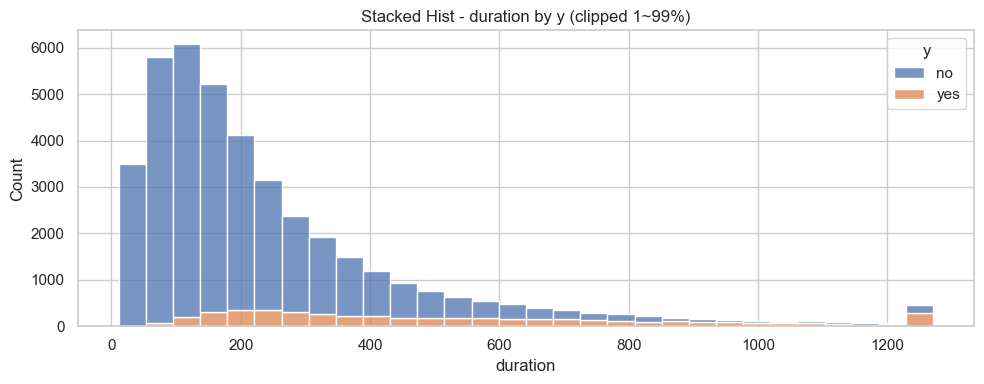

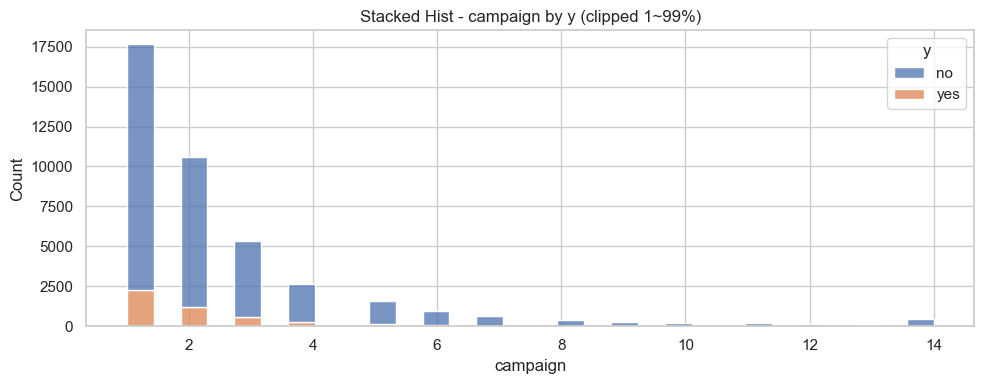

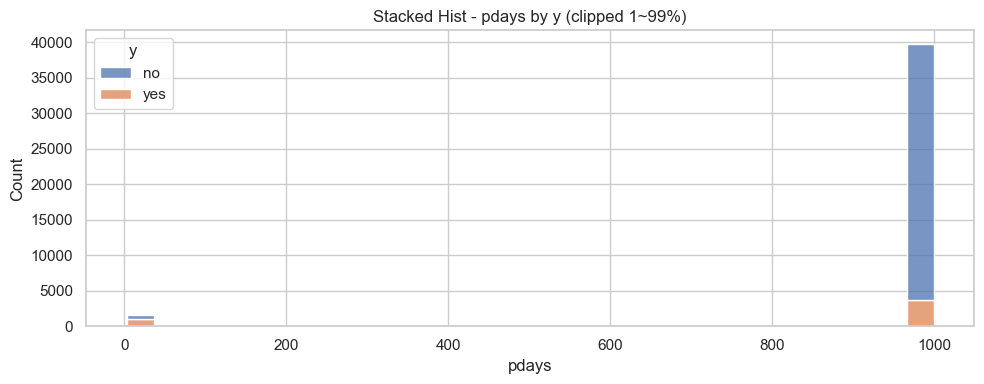

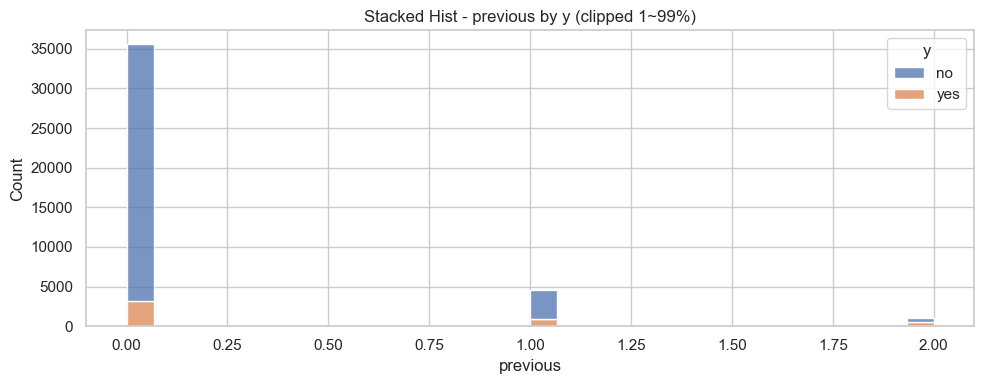

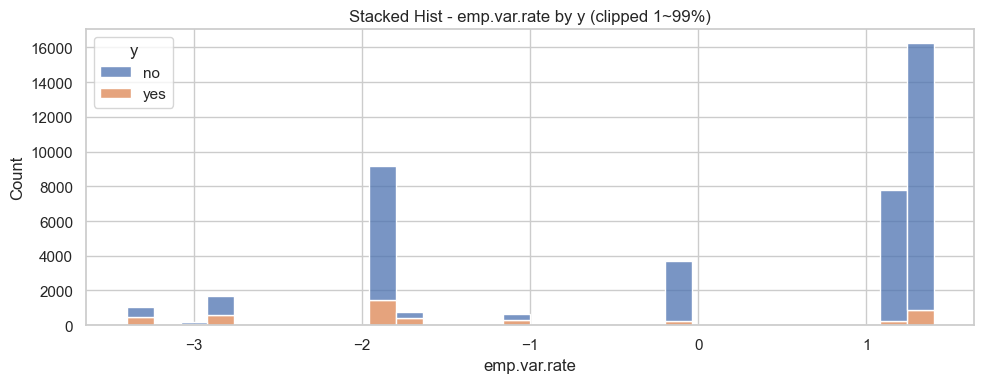

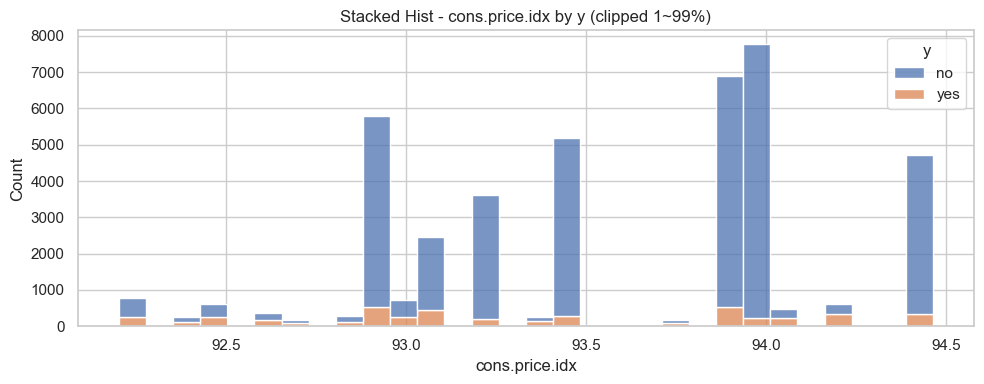

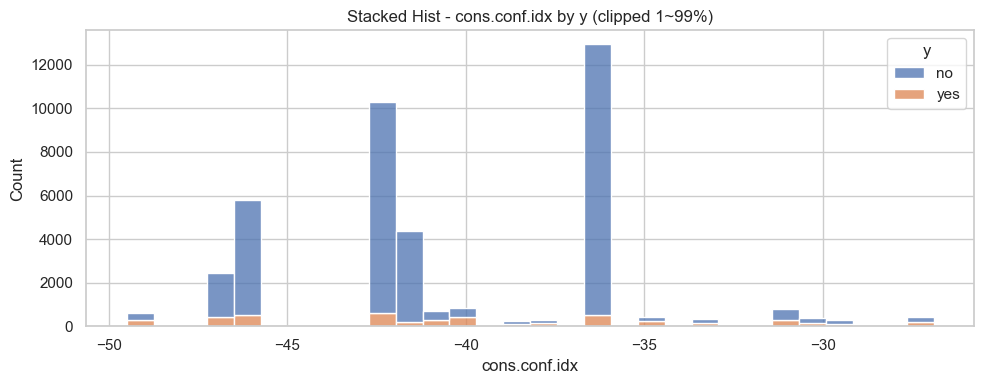

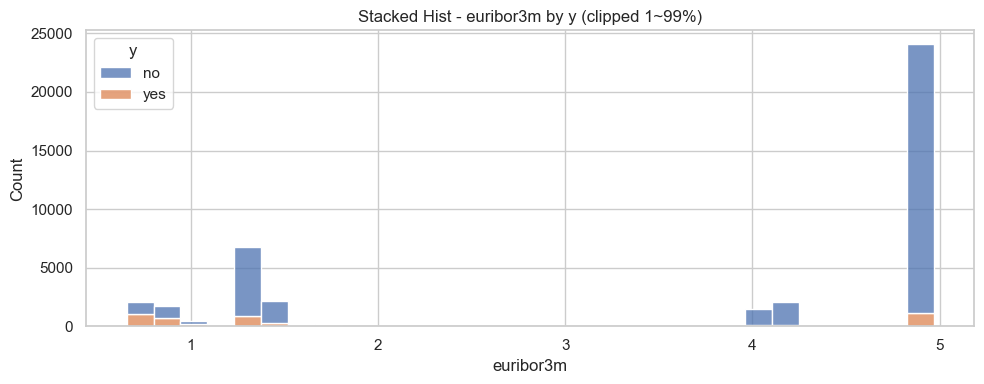

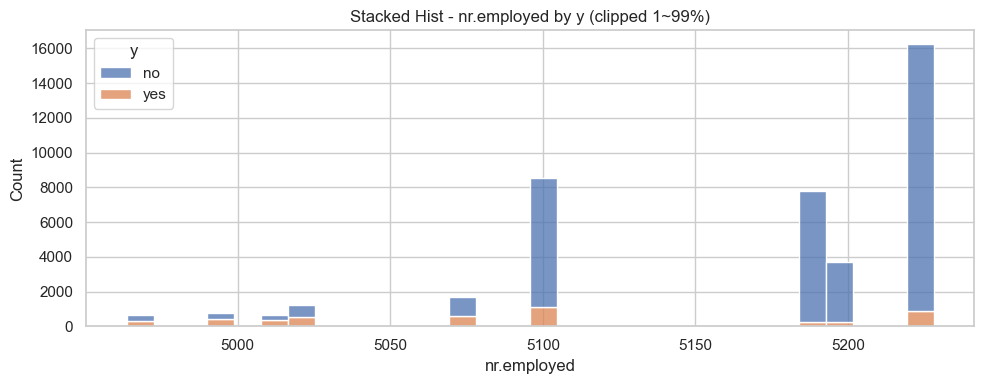

In [48]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 비교 기준(겹쳐볼 범주형 컬럼)
hue_col = "y"  # "contact", "month", "poutcome" 등으로 바꿔도 됨

# 분포 비교할 수치형 컬럼(원하는 것만 골라 써도 OK)
plot_cols = ["age", "duration", "campaign", "pdays", "previous",
             "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

# 존재하는 컬럼만 필터링
plot_cols = [c for c in plot_cols if c in bank_df.columns]

LOW_Q, HIGH_Q = 0.01, 0.99  # 시각화용 클리핑 범위(원본은 그대로)

for col in plot_cols:
    s = bank_df[col]
    lo, hi = s.quantile(LOW_Q), s.quantile(HIGH_Q)
    s_clip = s.clip(lo, hi)  # ✅ 시각화용만

    plt.figure(figsize=(10, 4))
    sns.histplot(
        x=s_clip,
        hue=bank_df[hue_col],
        bins=30,
        multiple="stack"
    )
    plt.title(f"Stacked Hist - {col} by {hue_col} (clipped {int(LOW_Q*100)}~{int(HIGH_Q*100)}%)")
    plt.tight_layout()
    plt.show()


#### 4-5) 수치형 히트맵 ###

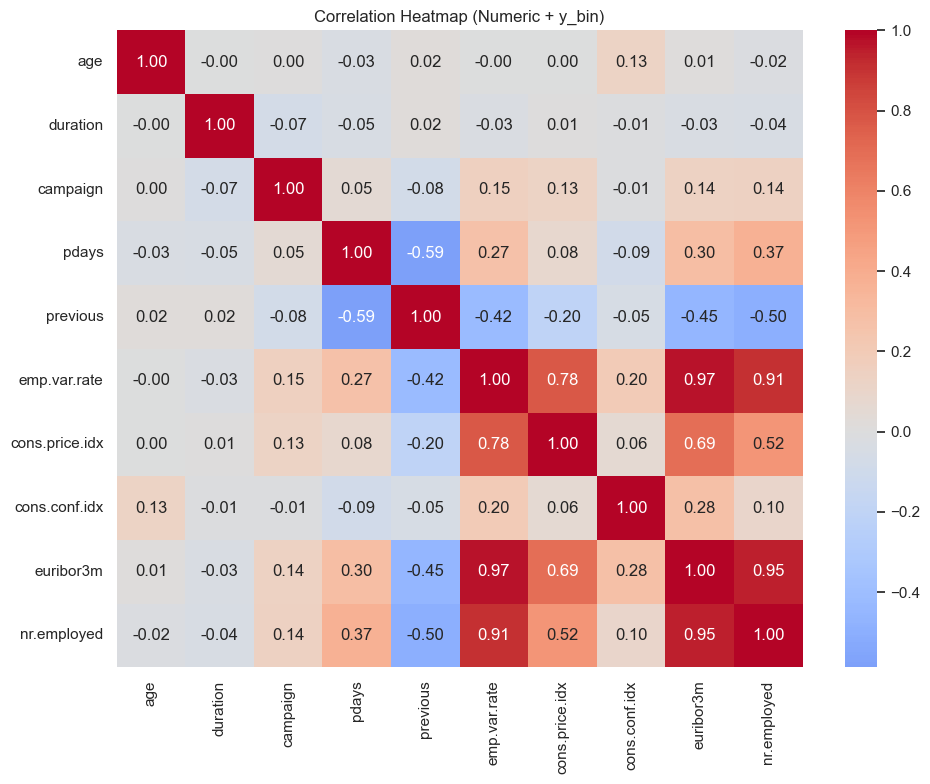

In [49]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 수치형만 뽑기
numeric_df = bank_df.select_dtypes(include=[np.number]).copy()

plt.figure(figsize=(10, 8))
sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap (Numeric + y_bin)")
plt.tight_layout()
plt.show()


**1) 히스토그램(수치형 분포)**

대부분 변수는 특정 구간에 관측치가 몰려 있으며, 특히 duration, campaign, pdays, previous는 한쪽으로 치우친 분포(왜도)가 뚜렷하다.

pdays는 999 근처에 강하게 집중, previous는 0에 집중되어 있어 일반적인 연속형 변수라기보다 이력/상태 정보를 담은 구조로 해석된다.

**2) 박스플롯(이상치 확인)**

IQR 기준으로 duration·campaign에서 상단 이상치가 많이 나타나며, 이는 오류라기보다 긴 꼬리를 가진 분포 특성의 영향이 크다.

**pdays(999 집중), previous(0 집중)**는 희소/특수값 특성 때문에 박스플롯이 눌려 보이며, 단순 제거보다는 의미 기반 처리 후보로 판단된다.

**3) 스택 히스토그램(y 기준 분포 비교)**

y는 no가 우세한 불균형 데이터로 보이며, 이후 평가에서 accuracy 외에도 F1/ROC-AUC 등을 함께 고려할 필요가 있다.

duration이 길수록 yes 비중이 상대적으로 커지는 경향, campaign은 접촉 횟수가 늘수록 yes 비중이 줄어드는 경향이 관찰되어 가입과 행동 패턴의 연관 가능성을 시사한다.

**4) 히트맵(수치형 상관관계)**

거시경제 변수들(emp.var.rate, euribor3m, nr.employed, cons.price.idx) 사이에 매우 높은 상관이 확인되어, 선형 모델에서는 다중공선성에 유의해야 한다.

pdays–previous는 음의 상관으로, 이전 접촉 이력이 있을수록 마지막 접촉 후 경과일이 짧아지는 구조가 반영된 것으로 해석된다.

#### 4-6) 목표변수 불균형 확인 ###

In [50]:
# y 클래스 개수/비율 확인
y_counts = bank_df["y"].value_counts()
y_ratio = (bank_df["y"].value_counts(normalize=True) * 100).round(2)

display(pd.DataFrame({"count": y_counts, "ratio(%)": y_ratio}))


,count,ratio(%)
y,,
no,36537,88.73
yes,4639,11.27


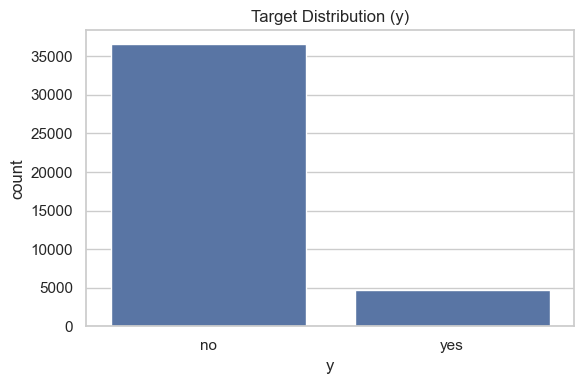

In [51]:
# 2) 시각화(막대그래프)로 한눈에 보기
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,4))
sns.countplot(data=bank_df, x="y")
plt.title("Target Distribution (y)")
plt.tight_layout()
plt.show()


완전히 치우쳐진 상황은 아니지만, 다른 데이터를 분석할 때 'no'쪽으로 많이 기울어질 수 있는 상황이다. 

#### 4-7) 데이터 리샘플링 ###

데이터를 SMOTE, SMOTETomek를 활용해서 리샘플링

In [52]:
#bank_df를 X, y로 분리하기
y = bank_df[["y"]].rename(columns = {"y":"class"})
X = bank_df.drop(columns=["y"])

#범주형 데이터를 원-핫 인코딩으로 변환(숫자형으로 변환)
X = pd.get_dummies(X, drop_first = False)

In [53]:
#train, test 분리, 형태 테스트 코드
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                   stratify = y,
                                                   shuffle = True,
                                                   test_size = 0.2,
                                                   random_state = 42
)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((32940, 63), (8236, 63), (32940, 1), (8236, 1))

In [54]:
#SMOTE 적용
smote = SMOTE(random_state = 42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

#SMOTE Tomek 적용
smt = SMOTETomek(random_state=42)
X_resampled_smt, y_resampled_smt = smt.fit_resample(X_train, y_train)

print("SMOTE 적용 결과 : ")
print(Counter(y_train_resampled['class']))
print("STOME + Tomek 적용 결과 :")
print(Counter(y_resampled_smt['class']))

SMOTE 적용 결과 : 
Counter({'no': 29229, 'yes': 29229})
STOME + Tomek 적용 결과 :
Counter({'no': 28990, 'yes': 28990})


### 5) 스케일링 : 숫자형 데이터 표준화 ###

In [55]:
# 위에서 SMOTE관련 코드를 작성하면서 X_train, X_test, y_train, y_test 관련된 코드는 작성된 상태에서 표준화를 진행하는 코드 작성

#bank_df에서 "y"를 제외하고, 숫자형 컬럼만 뽑기
num_cols = bank_df.drop(columns = ["y"]).select_dtypes(include = [np.number]).columns.tolist()

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

# 결과 테스트 코드
print("train 평균 (approx 0) :")
print(X_train_scaled[num_cols].mean().round(3))

print("test 표준편차 (approx 1) : ")
print(X_test_scaled[num_cols].std(ddof = 0).round(3))

train 평균 (approx 0) :
age              -0.0
duration          0.0
campaign         -0.0
pdays             0.0
previous          0.0
emp.var.rate     -0.0
cons.price.idx    0.0
cons.conf.idx     0.0
euribor3m        -0.0
nr.employed       0.0
dtype: float64
test 표준편차 (approx 1) : 
age               0.984
duration          1.035
campaign          1.001
pdays             1.010
previous          0.963
emp.var.rate      0.998
cons.price.idx    0.995
cons.conf.idx     0.999
euribor3m         0.996
nr.employed       0.990
dtype: float64


### 6) 인코딩 : 범주형 데이터 원-핫 인코딩 ###

In [56]:
X = bank_df.drop(columns = ["y"])
y = bank_df[["y"]].rename(columns = {"y": "class"})

X_train_raw, X_test_raw, y_train, y_test = train_test_split(X, y,
                                                            test_size = 0.2,
                                                            random_state = 42,
                                                            stratify = y
)

cat_cols = X_train_raw.select_dtypes(include = ["object", "category"]).columns.tolist()
print("범주형 컬럼", cat_cols)

X_train = pd.get_dummies(X_train_raw, columns = cat_cols, drop_first = False)
X_test = pd.get_dummies(X_test_raw, columns = cat_cols, drop_first = False)

X_test = X_test.reindex(columns = X_train.columns, fill_value = 0)
print("인코딩 후 shape : ", X_train.shape, X_test.shape)



범주형 컬럼 ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
인코딩 후 shape :  (32940, 63) (8236, 63)


### 7) 데이터 분할 : bank_df를 8:2 비율로 학습/평가용 분리 ###

In [57]:

# 8:2비율로 학습 & 평가 데이터 분리
X_train_division, X_valid, y_train_division, y_valid = train_test_split(
    X_train, y_train,
    test_size = 0.2, 
    random_state = 42,
    stratify = y_train
)


print("X_train_division : ", X_train_division.shape)
print("X_valid : ", X_valid.shape)
print("y_train_division : ", y_train_division.shape)
print("y_valid : ", y_valid)

X_train_division :  (26352, 63)
X_valid :  (6588, 63)
y_train_division :  (26352, 1)
y_valid :        class
6119     no
36240   yes
6776     no
19978    no
23351    no
...     ...
28732   yes
21749    no
4598     no
7378     no
17306    no

[6588 rows x 1 columns]


## 3. 모델 학습 및 최적화 ##

### 1) 선형모델 ###

In [58]:
import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, average_precision_score

# -----------------------------
# 1) y를 0/1로 변환 (no=0, yes=1)
#    - y가 DataFrame이면 'class' 컬럼 사용
#    - y가 Series/ndarray이면 그대로 처리
# -----------------------------
def to_binary_y(y):
    # DataFrame이면 'class' 1컬럼을 꺼내서 변환
    if isinstance(y, pd.DataFrame):
        if "class" in y.columns:
            y = y["class"]
        else:
            # 혹시 1컬럼짜리 DF면 첫 컬럼 사용
            y = y.iloc[:, 0]

    # Series/array -> numpy 1d
    y = np.array(y).ravel()

    # 문자열이면 매핑
    if y.dtype.kind in ["U", "S", "O"]:
        return np.where(y == "yes", 1, 0).astype(int)

    # 이미 0/1이면 그대로
    return y.astype(int)

y_train_bin = to_binary_y(y_train)
y_test_bin  = to_binary_y(y_test)

# -----------------------------
# 2) 모델 정의 (원본 그대로)
# -----------------------------
logit_l2 = LogisticRegression(
    penalty="l2",
    C=1.0,
    solver="liblinear",
    class_weight="balanced",  # 불균형 보정
    max_iter=1000,
    random_state=42
)

# -----------------------------
# 3) 학습/예측 (원본 변수명만 교체)
#    - y_train_final -> y_train
#    - X_train_final -> X_train
#    - y_valid/X_valid -> y_test/X_test
# -----------------------------
logit_l2.fit(X_train, y_train_bin)

test_proba = logit_l2.predict_proba(X_test)[:, 1]     # yes(1) 확률
test_pred  = (test_proba >= 0.5).astype(int)          # 임계값 0.5 기준 분류

# -----------------------------
# 4) 평가 출력 (원본 그대로)
# -----------------------------
print(classification_report(y_test_bin, test_pred, target_names=["no", "yes"]))
print("Confusion matrix:\n", confusion_matrix(y_test_bin, test_pred))
print("ROC-AUC:", roc_auc_score(y_test_bin, test_proba))
print("PR-AUC(AP):", average_precision_score(y_test_bin, test_proba))


              precision    recall  f1-score   support

          no       0.99      0.86      0.92      7308
         yes       0.45      0.91      0.60       928

    accuracy                           0.86      8236
   macro avg       0.72      0.88      0.76      8236
weighted avg       0.93      0.86      0.88      8236

Confusion matrix:
 [[6265 1043]
 [  85  843]]
ROC-AUC: 0.9401059361021459
PR-AUC(AP): 0.591555510679625


In [59]:
# y_train_division, y_valid 가 DataFrame이고 컬럼명이 "class" 인 상태라고 가정
y_train_bin = (y_train_division["class"] == "yes").astype(int).values.ravel()
y_valid_bin = (y_valid["class"] == "yes").astype(int).values.ravel()

# (안전) X_valid 컬럼 정렬이 X_train_division과 다르면 맞춰주기
X_valid = X_valid.reindex(columns=X_train_division.columns, fill_value=0)


In [60]:
def eval_clf(name, model, X_tr, y_tr, X_va, y_va):
    model.fit(X_tr, y_tr)
    proba = model.predict_proba(X_va)[:, 1]
    pred = (proba >= 0.5).astype(int)

    print(f"\n===== {name} =====")
    print("Accuracy :", accuracy_score(y_va, pred))
    print("Precision:", precision_score(y_va, pred, zero_division=0))
    print("Recall   :", recall_score(y_va, pred, zero_division=0))
    print("F1       :", f1_score(y_va, pred, zero_division=0))
    print("ROC-AUC  :", roc_auc_score(y_va, proba))
    print("\nConfusion Matrix\n", confusion_matrix(y_va, pred))


In [61]:
# 규제 없음(=기본 로지스틱)
logit_base = LogisticRegression(
    penalty=None, solver="lbfgs", max_iter=5000,
    class_weight="balanced", random_state=42
)

# Ridge(L2)
logit_l2 = LogisticRegression(
    penalty="l2", C=1.0, solver="lbfgs", max_iter=5000,
    class_weight="balanced", random_state=42
)

# Lasso(L1) - solver 주의(saga or liblinear)
logit_l1 = LogisticRegression(
    penalty="l1", C=1.0, solver="saga", max_iter=5000,
    class_weight="balanced", random_state=42
)

eval_clf("Logistic (no penalty)", logit_base, X_train_division, y_train_bin, X_valid, y_valid_bin)
eval_clf("Logistic Ridge (L2)",   logit_l2,   X_train_division, y_train_bin, X_valid, y_valid_bin)
eval_clf("Logistic Lasso (L1)",   logit_l1,   X_train_division, y_train_bin, X_valid, y_valid_bin)


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



===== Logistic (no penalty) =====
Accuracy : 0.8602003642987249
Precision: 0.43915703602991163
Recall   : 0.8706199460916442
F1       : 0.5838228648892906
ROC-AUC  : 0.936392566437945

Confusion Matrix
 [[5021  825]
 [  96  646]]


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



===== Logistic Ridge (L2) =====
Accuracy : 0.8598967820279295
Precision: 0.43847722637661457
Recall   : 0.8692722371967655
F1       : 0.5829191143244464
ROC-AUC  : 0.9363782732543182

Confusion Matrix
 [[5020  826]
 [  97  645]]

===== Logistic Lasso (L1) =====
Accuracy : 0.8469945355191257
Precision: 0.411214953271028
Recall   : 0.8301886792452831
F1       : 0.55
ROC-AUC  : 0.9230212931550406

Confusion Matrix
 [[4964  882]
 [ 126  616]]


In [62]:
# 예: L1 모델을 기준으로 계수 확인 (원하면 logit_l2로 바꿔도 됨)
best_model = logit_l1
best_model.fit(X_train_division, y_train_bin)

coef = best_model.coef_.ravel()
coef_df = pd.DataFrame({
    "feature": X_train_division.columns,
    "coef": coef,
    "abs_coef": np.abs(coef)
}).sort_values("abs_coef", ascending=False)

print("\n[상위 영향 큰 컬럼 TOP 15]")
display(coef_df.head(15))

print("\n[yes(1)로 밀어주는 컬럼 TOP 10]")
display(coef_df.sort_values("coef", ascending=False).head(10))

print("\n[no(0)로 밀어주는 컬럼 TOP 10]")
display(coef_df.sort_values("coef", ascending=True).head(10))

# L1에서 0이 된 컬럼 개수(=자동으로 덜 중요하다고 판단)
zero_cnt = (coef_df["coef"] == 0).sum()
print(f"\nL1에서 coef=0인 컬럼 수: {zero_cnt} / {len(coef_df)}")



[상위 영향 큰 컬럼 TOP 15]


,feature,coef,abs_coef
5,emp.var.rate,-0.304931,0.304931
8,euribor3m,-0.294536,0.294536
6,cons.price.idx,0.218121,0.218121
51,month_may,-0.120878,0.120878
43,contact_cellular,0.058362,0.058362
44,contact_telephone,-0.055461,0.055461
11,job_blue-collar,-0.049825,0.049825
34,default_no,0.048136,0.048136
2,campaign,-0.046524,0.046524
35,default_unknown,-0.045221,0.045221



[yes(1)로 밀어주는 컬럼 TOP 10]


,feature,coef,abs_coef
6,cons.price.idx,0.218121,0.218121
43,contact_cellular,0.058362,0.058362
34,default_no,0.048136,0.048136
32,education_university.degree,0.042846,0.042846
24,marital_single,0.041967,0.041967
7,cons.conf.idx,0.040495,0.040495
50,month_mar,0.038815,0.038815
10,job_admin.,0.024792,0.024792
45,month_apr,0.024391,0.024391
15,job_retired,0.019836,0.019836



[no(0)로 밀어주는 컬럼 TOP 10]


,feature,coef,abs_coef
5,emp.var.rate,-0.304931,0.304931
8,euribor3m,-0.294536,0.294536
51,month_may,-0.120878,0.120878
44,contact_telephone,-0.055461,0.055461
11,job_blue-collar,-0.049825,0.049825
2,campaign,-0.046524,0.046524
35,default_unknown,-0.045221,0.045221
23,marital_married,-0.032511,0.032511
28,education_basic.9y,-0.026905,0.026905
17,job_services,-0.014617,0.014617



L1에서 coef=0인 컬럼 수: 2 / 63


In [63]:
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    roc_auc_score, f1_score, accuracy_score,
    precision_score, recall_score, confusion_matrix
)

# -----------------------
# 1) y (no/yes) -> 0/1 변환
# -----------------------
def y_to_01(y):
    """y가 DataFrame/Series/ndarray 어떤 형태든 들어와도 0/1로 변환"""
    if isinstance(y, pd.DataFrame):
        y = y.iloc[:, 0]
    y = pd.Series(np.array(y).ravel()).astype(str).str.strip().str.lower()
    y = y.map({"no": 0, "yes": 1})

    if y.isna().any():
        raise ValueError("y 값에 'yes/no' 외 값이 있어 0/1 변환 실패. y의 고유값을 확인하세요.")
    return y.astype(int).values

y_train_01 = y_to_01(y_train)
y_test_01  = y_to_01(y_test)

# (있다면) 8:2로 나눈 학습/검증 세트도 같이 평가
use_valid = all(name in globals() for name in ["X_train_final", "X_valid", "y_train_final", "y_valid"])
if use_valid:
    y_train_final_01 = y_to_01(y_train_final)
    y_valid_01       = y_to_01(y_valid)

# -----------------------
# 2) 평가 함수
# -----------------------
def eval_model(model, X_eval, y_eval, threshold=0.5):
    """확률 예측 -> threshold로 class 예측 후 지표 계산"""
    proba = model.predict_proba(X_eval)[:, 1]
    pred = (proba >= threshold).astype(int)

    return {
        "AUC": roc_auc_score(y_eval, proba),
        "F1": f1_score(y_eval, pred),
        "Accuracy": accuracy_score(y_eval, pred),
        "Precision": precision_score(y_eval, pred, zero_division=0),
        "Recall": recall_score(y_eval, pred),
        "TN,FP,FN,TP": confusion_matrix(y_eval, pred).ravel()
    }

# -----------------------
# 3) 모델 후보 + 하이퍼파라미터 탐색
#   - C: 규제 강도 (C↑ 규제 약함, C↓ 규제 강함)
# -----------------------
C_grid = np.logspace(-4, 2, 15)

candidates = [
    ("Logistic(L2 base)", Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(penalty="l2", C=1.0, solver="lbfgs", max_iter=5000))
    ]), None),

    ("Ridge(L2 tuned)", Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(penalty="l2", solver="lbfgs", max_iter=5000))
    ]), {"model__C": C_grid}),

    ("Lasso(L1 tuned)", Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(penalty="l1", solver="saga", max_iter=8000))
    ]), {"model__C": C_grid}),
]

results = []

# -----------------------
# 4) 학습 + (선택) 검증 + 테스트 평가
# -----------------------
for name, pipe, param_grid in candidates:
    if param_grid is None:
        # 기본 모델
        pipe.fit(X_train, y_train_01)
        best_model = pipe
        best_param = None
    else:
        # CV로 최적화 (AUC 기준)
        gs = GridSearchCV(
            pipe,
            param_grid=param_grid,
            scoring="roc_auc",
            cv=5,
            n_jobs=-1
        )
        gs.fit(X_train, y_train_01)
        best_model = gs.best_estimator_
        best_param = gs.best_params_

    row = {"model": name, "best_param": best_param}

    # (있으면) valid 평가
    if use_valid:
        row.update({f"valid_{k}": v for k, v in eval_model(best_model, X_valid, y_valid_01).items()})

    # test 평가
    row.update({f"test_{k}": v for k, v in eval_model(best_model, X_test, y_test_01).items()})

    results.append(row)

results_df = pd.DataFrame(results)

# 보기 좋게 정렬: test_AUC 기준 내림차순
results_df = results_df.sort_values("test_AUC", ascending=False)
print(results_df[["model", "best_param", "test_AUC", "test_F1", "test_Accuracy", "test_Precision", "test_Recall", "test_TN,FP,FN,TP"]])

# -----------------------
# 5) 가장 좋은 모델의 "중요 변수" (계수) 확인
# -----------------------
best_name = results_df.iloc[0]["model"]
print("\n[Best Model] :", best_name)

# best 모델 다시 확보
# (위 루프에서 best 모델을 저장해두지 않았으니 재학습/재탐색로 간단히 맞춤)
def get_best_estimator_by_name(best_name):
    for name, pipe, param_grid in candidates:
        if name == best_name:
            if param_grid is None:
                pipe.fit(X_train, y_train_01)
                return pipe
            else:
                gs = GridSearchCV(pipe, param_grid, scoring="roc_auc", cv=5, n_jobs=-1)
                gs.fit(X_train, y_train_01)
                return gs.best_estimator_
    raise ValueError("best model name not found")

best_est = get_best_estimator_by_name(best_name)

coef = best_est.named_steps["model"].coef_.ravel()
feat_names = X_train.columns if isinstance(X_train, pd.DataFrame) else [f"x{i}" for i in range(X_train.shape[1])]
coef_s = pd.Series(coef, index=feat_names).sort_values(key=np.abs, ascending=False)

print("\n[계수 절대값 TOP 15]")
print(coef_s.head(15))

# L1이면 선택된 변수 개수(0이 아닌 계수)
if "Lasso" in best_name:
    print("\n[Lasso 선택된 feature 수(0이 아닌 계수)] :", (coef_s != 0).sum())


               model                        best_param  test_AUC   test_F1  \
0  Logistic(L2 base)                              None  0.939000  0.513390   
2    Lasso(L1 tuned)  {'model__C': 1.9306977288832496}  0.938988  0.510444   
1    Ridge(L2 tuned)               {'model__C': 100.0}  0.938983  0.512720   

   test_Accuracy  test_Precision  test_Recall       test_TN,FP,FN,TP  
0       0.909543        0.651741     0.423491  [7098, 210, 535, 393]  
2       0.908936        0.647351     0.421336  [7095, 213, 537, 391]  
1       0.909301        0.649587     0.423491  [7096, 212, 535, 393]  

[Best Model] : Logistic(L2 base)

[계수 절대값 TOP 15]
emp.var.rate        -2.496889
duration             1.220304
cons.price.idx       1.117408
euribor3m            0.588152
month_aug            0.294566
nr.employed          0.228639
month_mar            0.226088
month_may           -0.208708
pdays               -0.186210
contact_telephone   -0.155147
contact_cellular     0.155147
month_jun           -0

### 2) 비선형모델 ###

In [64]:
import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

# 1) y 변환 (no/yes -> 0/1)
def to_binary(y):
    if isinstance(y, (pd.Series, pd.DataFrame)):
        y_ = y.iloc[:, 0] if isinstance(y, pd.DataFrame) else y
        if y_.dtype == "object":
            return y_.map({"no": 0, "yes": 1}).astype(int).values
        return y_.astype(int).values

    y = np.array(y)
    if y.dtype.kind in ("U", "S", "O"):
        return pd.Series(y).map({"no": 0, "yes": 1}).astype(int).values
    return y.astype(int)

y_train_bin = to_binary(y_train)
y_test_bin  = to_binary(y_test)

# 2) bool 컬럼 처리: 0/1 숫자화 (X_train/X_test 동시에)
bool_cols = X_train.select_dtypes(include=["bool"]).columns.tolist()

X_train_fix = X_train.copy()
X_test_fix  = X_test.copy()

for c in bool_cols:
    X_train_fix[c] = X_train_fix[c].astype(int)
    X_test_fix[c]  = X_test_fix[c].astype(int)

# 3) 컬럼 리스트 재정의 (bool은 이제 numeric으로 들어감)
num_cols2 = X_train_fix.select_dtypes(include=[np.number]).columns.tolist()
cat_cols  = X_train_fix.select_dtypes(exclude=[np.number]).columns.tolist()

print("num_cols2 개수:", len(num_cols2))
print("cat_cols 개수 :", len(cat_cols))
print("bool_cols(0/1로 변환됨):", len(bool_cols))

# 4) 평가 함수
def evaluate_clf(model, X_test, y_test_bin, name="model"):
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)

    acc = accuracy_score(y_test_bin, pred)
    prec = precision_score(y_test_bin, pred, zero_division=0)
    rec = recall_score(y_test_bin, pred, zero_division=0)
    f1 = f1_score(y_test_bin, pred, zero_division=0)
    auc = roc_auc_score(y_test_bin, proba)
    tn, fp, fn, tp = confusion_matrix(y_test_bin, pred).ravel()

    print(f"\n[{name}]")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1       : {f1:.4f}")
    print(f"AUC      : {auc:.4f}")
    print(f"Confusion Matrix [TN, FP, FN, TP] = [{tn}, {fp}, {fn}, {tp}]")

# 5) Polynomial (numeric만) + OneHot (categorical) + Logistic
num_poly_tf = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("scaler", StandardScaler())
])

categorical_tf = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocess_poly = ColumnTransformer(
    transformers=[
        ("num", num_poly_tf, num_cols2),
        ("cat", categorical_tf, cat_cols)
    ],
    remainder="drop"
)

poly_lr = Pipeline(steps=[
    ("prep", preprocess_poly),
    ("model", LogisticRegression(
        solver="saga",
        max_iter=5000,
        class_weight="balanced",
        n_jobs=-1
    ))
])

# 학습 + 평가
poly_lr.fit(X_train_fix, y_train_bin)
evaluate_clf(poly_lr, X_test_fix, y_test_bin, "Polynomial(deg=2, num only) + Logistic(class_weight)")


num_cols2 개수: 63
cat_cols 개수 : 0
bool_cols(0/1로 변환됨): 53

[Polynomial(deg=2, num only) + Logistic(class_weight)]
Accuracy : 0.8704
Precision: 0.4607
Recall   : 0.8782
F1       : 0.6044
AUC      : 0.9363
Confusion Matrix [TN, FP, FN, TP] = [6354, 954, 113, 815]


### 3) 트리/앙상블 ###

In [65]:
import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
)

# -----------------------------
# 0) 평가 함수
# -----------------------------
def evaluate_clf(model, X_te, y_te, name="model"):
    pred = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, 1] if hasattr(model, "predict_proba") else None

    out = {
        "model": name,
        "test_Accuracy": accuracy_score(y_te, pred),
        "test_Precision": precision_score(y_te, pred, zero_division=0),
        "test_Recall": recall_score(y_te, pred, zero_division=0),
        "test_F1": f1_score(y_te, pred, zero_division=0),
        "test_AUC": roc_auc_score(y_te, proba) if proba is not None else np.nan,
        "test_TN,FP,FN,TP": confusion_matrix(y_te, pred).ravel().tolist()
    }
    return out


# -----------------------------
# 1) (중요) bool dtype 안전 처리
#   - SimpleImputer가 bool dtype에서 터질 수 있어서 int로 바꿔줌
# -----------------------------
def fix_bool_to_int(df):
    df = df.copy()
    bool_cols = df.select_dtypes(include=["bool"]).columns
    if len(bool_cols) > 0:
        df[bool_cols] = df[bool_cols].astype(int)
    return df

X_tr = fix_bool_to_int(X_train_fix)
X_te = fix_bool_to_int(X_test_fix)

y_tr = np.array(y_train_bin).ravel().astype(int)
y_te = np.array(y_test_bin).ravel().astype(int)


# -----------------------------
# 2) 전처리: 수치/범주 분리
#   - 트리/앙상블에서는 보통 스케일링은 필수 아님
#   - 결측치 처리 + (범주형 있으면) 원핫만 수행
# -----------------------------
num_tf = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

cat_tf = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    # sklearn 버전에 따라 sparse_output/sparse 파라미터가 다름 → 안전 처리
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocess = ColumnTransformer(
    transformers=[
        ("num", num_tf, num_cols2),
        ("cat", cat_tf, cat_cols)
    ],
    remainder="drop"
)

# 전처리를 "미리" 수행해서, CatBoost를 sklearn Pipeline 밖에서 돌릴 수 있게 함
X_tr_p = preprocess.fit_transform(X_tr)
X_te_p = preprocess.transform(X_te)

# 원핫이 섞이면 sparse가 될 수 있음 → CatBoost 대비해서 dense로 변환(필요할 때만)
if hasattr(X_tr_p, "toarray"):
    X_tr_p_dense = X_tr_p.toarray()
    X_te_p_dense = X_te_p.toarray()
else:
    X_tr_p_dense = X_tr_p
    X_te_p_dense = X_te_p


# -----------------------------
# 3) 모델 정의
# -----------------------------
models = {}

models["DecisionTree"] = DecisionTreeClassifier(
    random_state=42,
    class_weight="balanced",
    max_depth=None,
    min_samples_leaf=10
)

models["RandomForest"] = RandomForestClassifier(
    random_state=42,
    n_estimators=400,
    class_weight="balanced_subsample",
    n_jobs=-1,
    min_samples_leaf=10
)

# CatBoost는 "전처리된 배열"에 직접 학습 (Pipeline 안에 넣지 않음)
try:
    from catboost import CatBoostClassifier
    models["CatBoost"] = CatBoostClassifier(
        random_seed=42,
        iterations=800,
        learning_rate=0.05,
        depth=6,
        loss_function="Logloss",
        eval_metric="AUC",
        verbose=0,
        auto_class_weights="Balanced"
    )
except Exception as e:
    print("[CatBoost] 미설치/에러로 스킵:", e)

# (옵션) XGBoost
try:
    from xgboost import XGBClassifier
    models["XGBoost"] = XGBClassifier(
        random_state=42,
        n_estimators=600,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.9,
        colsample_bytree=0.9,
        reg_lambda=1.0,
        # 이진분류 + 확률 출력
        objective="binary:logistic",
        eval_metric="auc"
    )
except Exception as e:
    print("[XGBoost] 미설치/에러로 스킵. 필요 시: pip install xgboost")

# (옵션) LightGBM
try:
    from lightgbm import LGBMClassifier
    models["LightGBM"] = LGBMClassifier(
        random_state=42,
        n_estimators=800,
        learning_rate=0.03,
        num_leaves=31,
        subsample=0.9,
        colsample_bytree=0.9,
        class_weight="balanced"
    )
except Exception as e:
    print("[LightGBM] 미설치/에러로 스킵. 필요 시: pip install lightgbm")


# -----------------------------
# 4) 학습 + 평가
#   - sklearn 모델은 sparse도 OK
#   - CatBoost는 dense 권장
# -----------------------------
results = []

for name, clf in models.items():
    if name == "CatBoost":
        clf.fit(X_tr_p_dense, y_tr)
        results.append(evaluate_clf(clf, X_te_p_dense, y_te, name))
    else:
        clf.fit(X_tr_p, y_tr)
        results.append(evaluate_clf(clf, X_te_p, y_te, name))

results_df = pd.DataFrame(results).sort_values(["test_AUC", "test_F1"], ascending=False)
print("\n===== 모델 비교 (AUC, F1 우선 정렬) =====")
print(results_df)


# -----------------------------
# 5) (선택) 중요 변수 확인
# -----------------------------
# feature name 가져오기 (가능하면)
try:
    feat_names = preprocess.get_feature_names_out()
except Exception:
    feat_names = [f"f{i}" for i in range(X_tr_p.shape[1])]

# RandomForest/DecisionTree
for key in ["DecisionTree", "RandomForest"]:
    if key in models and hasattr(models[key], "feature_importances_"):
        imp = pd.Series(models[key].feature_importances_, index=feat_names).sort_values(ascending=False)
        print(f"\n[{key}] 중요도 TOP 15")
        print(imp.head(15))

# CatBoost
if "CatBoost" in models:
    cb = models["CatBoost"]
    try:
        imp = pd.Series(cb.get_feature_importance(), index=feat_names).sort_values(ascending=False)
        print("\n[CatBoost] 중요도 TOP 15")
        print(imp.head(15))
    except Exception as e:
        print("[CatBoost] 중요도 추출 실패:", e)


[XGBoost] 미설치/에러로 스킵. 필요 시: pip install xgboost
[LightGBM] 미설치/에러로 스킵. 필요 시: pip install lightgbm

===== 모델 비교 (AUC, F1 우선 정렬) =====
          model  test_Accuracy  test_Precision  test_Recall   test_F1  \
2      CatBoost       0.880525        0.484018     0.913793  0.632836   
1  RandomForest       0.873482        0.468612     0.917026  0.620262   
0  DecisionTree       0.870568        0.459649     0.846983  0.595906   

   test_AUC       test_TN,FP,FN,TP  
2  0.951980   [6404, 904, 80, 848]  
1  0.948588   [6343, 965, 77, 851]  
0  0.899205  [6384, 924, 142, 786]  

[DecisionTree] 중요도 TOP 15
num__duration                         0.471797
num__nr.employed                      0.251804
num__cons.conf.idx                    0.085866
num__euribor3m                        0.059741
num__age                              0.025642
num__month_oct                        0.013068
num__campaign                         0.011532
num__pdays                            0.007413
num__cons.price.idx    

In [66]:
import numpy as np
import pandas as pd

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier


# -------------------------
# 0) y를 0/1로 안전 변환
# -------------------------
def to_binary_y(y):
    if isinstance(y, pd.DataFrame):
        y = y.iloc[:, 0]
    y = np.array(y).ravel()
    if y.dtype.kind in ["U", "S", "O"]:      # 문자열이면
        return np.where(y == "yes", 1, 0).astype(int)
    return y.astype(int)


# -------------------------
# 1) 평가 함수 (AUC/PR-AUC 포함)
# -------------------------
def evaluate_clf(model, X_te, y_te, name="model"):
    proba = model.predict_proba(X_te)[:, 1] if hasattr(model, "predict_proba") else None
    pred = model.predict(X_te)

    acc = accuracy_score(y_te, pred)
    pre = precision_score(y_te, pred, zero_division=0)
    rec = recall_score(y_te, pred, zero_division=0)
    f1  = f1_score(y_te, pred, zero_division=0)
    auc = roc_auc_score(y_te, proba) if proba is not None else np.nan
    ap  = average_precision_score(y_te, proba) if proba is not None else np.nan
    cm  = confusion_matrix(y_te, pred)

    return {
        "model": name,
        "test_Accuracy": acc,
        "test_Precision": pre,
        "test_Recall": rec,
        "test_F1": f1,
        "test_ROC_AUC": auc,
        "test_PR_AUC(AP)": ap,
        "TN_FP_FN_TP": cm.ravel().tolist()  # [TN, FP, FN, TP]
    }


# -------------------------
# 2) 준비: y 변환 + CV 설정
# -------------------------
y_train_bin = to_binary_y(y_train)
y_test_bin  = to_binary_y(y_test)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 여러 지표를 같이 보되, refit은 ROC-AUC로(불균형 데이터에 유리)
scoring = {
    "AUC": "roc_auc",
    "F1": "f1",
    "AP": "average_precision"
}


# -------------------------
# 3) (1) 로지스틱 튜닝 (기본/강력 baseline)
#    - 스케일링 필요
# -------------------------
pipe_logit = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(solver="saga", max_iter=5000, class_weight="balanced", random_state=42))
])

param_logit = {
    "model__penalty": ["l1", "l2"],
    "model__C": np.logspace(-3, 2, 10)     # 0.001 ~ 100
}

gs_logit = GridSearchCV(
    pipe_logit,
    param_grid=param_logit,
    scoring=scoring,
    refit="AUC",
    cv=cv,
    n_jobs=-1,
    verbose=0
)
gs_logit.fit(X_train, y_train_bin)


# -------------------------
# 4) (2) DecisionTree 튜닝
#    - 스케일링 불필요
# -------------------------
pipe_dt = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeClassifier(class_weight="balanced", random_state=42))
])

param_dt = {
    "model__max_depth": [None, 3, 5, 8, 12],
    "model__min_samples_split": [2, 10, 30, 100],
    "model__min_samples_leaf": [1, 5, 10, 30],
}

gs_dt = GridSearchCV(
    pipe_dt,
    param_grid=param_dt,
    scoring=scoring,
    refit="AUC",
    cv=cv,
    n_jobs=-1,
    verbose=0
)
gs_dt.fit(X_train, y_train_bin)


# -------------------------
# 5) (3) RandomForest 튜닝
#    - 스케일링 불필요
# -------------------------
pipe_rf = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=-1))
])

param_rf = {
    "model__n_estimators": [300, 600],
    "model__max_depth": [None, 6, 12],
    "model__min_samples_split": [2, 10, 30],
    "model__min_samples_leaf": [1, 5, 10],
    "model__max_features": ["sqrt", 0.5]
}

gs_rf = GridSearchCV(
    pipe_rf,
    param_grid=param_rf,
    scoring=scoring,
    refit="AUC",
    cv=cv,
    n_jobs=-1,
    verbose=0
)
gs_rf.fit(X_train, y_train_bin)


# -------------------------
# 6) 결과 정리(테스트 평가)
# -------------------------
best_models = {
    "Logistic(tuned)": gs_logit.best_estimator_,
    "DecisionTree(tuned)": gs_dt.best_estimator_,
    "RandomForest(tuned)": gs_rf.best_estimator_,
}

results = []
for name, model in best_models.items():
    results.append(evaluate_clf(model, X_test, y_test_bin, name=name))

results_df = pd.DataFrame(results).sort_values(["test_ROC_AUC", "test_F1"], ascending=False)
print("===== 튜닝 결과(테스트 기준) : AUC -> F1 순 정렬 =====")
print(results_df)

print("\n[Best Params]")
print("Logistic:", gs_logit.best_params_)
print("DecisionTree:", gs_dt.best_params_)
print("RandomForest:", gs_rf.best_params_)


===== 튜닝 결과(테스트 기준) : AUC -> F1 순 정렬 =====
                 model  test_Accuracy  test_Precision  test_Recall   test_F1  \
2  RandomForest(tuned)       0.885381        0.495238     0.896552  0.638037   
1  DecisionTree(tuned)       0.842885        0.413516     0.942888  0.574901   
0      Logistic(tuned)       0.863890        0.448643     0.908405  0.600641   

   test_ROC_AUC  test_PR_AUC(AP)            TN_FP_FN_TP  
2      0.951692         0.674993   [6460, 848, 96, 832]  
1      0.943591         0.636608  [6067, 1241, 53, 875]  
0      0.940347         0.592581  [6272, 1036, 85, 843]  

[Best Params]
Logistic: {'model__C': np.float64(0.1668100537200059), 'model__penalty': 'l1'}
DecisionTree: {'model__max_depth': 8, 'model__min_samples_leaf': 30, 'model__min_samples_split': 100}
RandomForest: {'model__max_depth': None, 'model__max_features': 0.5, 'model__min_samples_leaf': 10, 'model__min_samples_split': 30, 'model__n_estimators': 600}


## 4. 평가 및 최종 제출 ##

### 1) 평가지표 ###
: accuracy, precision, recall, f1-score, auc-roc, confusion matrix 계산

1. 평가 목적
 해당 과정의 목적은 정기예금 가입을 얼마나 잘 예측하는지 확인하고, 다양한 모델의 성능을 accuracy, precision, recall, f1-score, auc-roc, confusion matrix로 비교·해석하여 **최종 제출 강조점(개선방안 도출)**에 적합한 모델을 선정하는 것입니다.
은행 마케팅 데이터는 일반적으로 yes 비율이 낮은 불균형 데이터이므로, Accuracy 단독 해석은 위험하며 Recall / Precision / F1 / (가능하면 PR-AUC) 중심으로 판단해야 합니다.

2. 평가지표 해석 기준
Accuracy: 전체 예측 중 맞춘 비율
Precision (정밀도): “yes”라고 예측한 것 중 실제 yes 비율
Recall (재현율): 실제 yes 중 모델이 잡아낸 비율
F1-score: Precision과 Recall의 균형 지표(조화평균)
ROC-AUC: threshold 변화에도 견디는 순위화(분리) 능력
Confusion Matrix [TN, FP, FN, TP]
FP 증가: 가입 안 할 고객에 연락 ↑ → 비용/피로도 ↑
FN 증가: 가입할 고객을 놓침 ↑ → 기회손실 ↑

3. 모델별 성능 결과 요약 (테스트 기준)
3.1 비선형 모델 (Polynomial Regression)
Polynomial(deg=2, num only) + LogisticRegression(class_weight)
Accuracy: 0.8704
Precision: 0.4607
Recall: 0.8782
F1: 0.6044
AUC: 0.9363
Confusion Matrix [TN, FP, FN, TP] = [6354, 954, 113, 815]

해석
Recall이 매우 높아(0.8782) 가입 가능 고객을 넓게 잡는 탐색형 모델에 적합합니다.
다만 FP(954)가 상대적으로 커져 불필요한 연락 증가(비용/피로도)가 발생할 수 있습니다.
즉, 신규 고객을 넓게 발굴하는 1차 타겟 풀 생성에는 유리하나, 고비용 채널(콜센터)에서는 임계값 조정이 필요합니다.

3.2 트리/앙상블 (기본 비교)
CatBoost
Acc: 0.880525 / Prec: 0.484018 / Rec: 0.913793 / F1: 0.632836 / AUC: 0.951980
CM: [6404, 904, 80, 848]
RandomForest
Acc: 0.873482 / Prec: 0.468612 / Rec: 0.917026 / F1: 0.620262 / AUC: 0.948588
CM: [6343, 965, 77, 851]
DecisionTree
Acc: 0.870568 / Prec: 0.459649 / Rec: 0.846983 / F1: 0.595906 / AUC: 0.899205
CM: [6384, 924, 142, 786]

해석
CatBoost가 전반적으로 가장 균형이 좋고(AUC/F1 높음), FN이 낮아(80) 가입자를 놓치는 비율이 작습니다.
RandomForest는 Recall이 높지만 FP가 더 커(965) 비용 측면에서 약간 불리할 수 있습니다.
DecisionTree는 단순하지만 AUC가 낮아 **분리 성능(순위화)**이 떨어집니다.

3.3 하이퍼파라미터 튜닝 결과 (AUC → F1 우선 정렬)
RandomForest(tuned)
Acc: 0.885381 / Prec: 0.495238 / Rec: 0.896552 / F1: 0.638037
ROC-AUC: 0.951692 / PR-AUC(AP): 0.674993
CM: [6460, 848, 96, 832]
Logistic(tuned)
Acc: 0.863890 / Prec: 0.448643 / Rec: 0.908405 / F1: 0.600641
ROC-AUC: 0.940347 / PR-AUC(AP): 0.592581
CM: [6272, 1036, 85, 843]
DecisionTree(tuned)
Acc: 0.842885 / Prec: 0.413516 / Rec: 0.942888 / F1: 0.574901
ROC-AUC: 0.943591 / PR-AUC(AP): 0.636608
CM: [6007, 1241, 53, 875]

해석(핵심 결론)
최종 성능 1순위는 RandomForest(tuned) 입니다.
F1이 가장 높고(0.638), PR-AUC도 가장 높아(0.675) yes 타겟팅 품질이 우수합니다.
FP를 848로 억제하면서 TP 832를 확보하여 비용(불필요 연락)과 성과(가입자 확보)의 균형이 가장 좋습니다.
DecisionTree(tuned)는 Recall이 매우 높아(0.943) “놓치지 않기”는 좋지만, FP가 1241로 커져 과도한 연락/비용 증가 리스크가 큽니다.
Logistic(tuned)는 안정적이나 FP가 1036으로 커서, 고객 피로도/비용 관리 측면에서 튜닝 RF 대비 불리합니다.

4. 마케팅 관점 시사점 (기존 고객 + 신규 고객)
신규 고객 확보(탐색형): Recall 중심이 유리합니다.
기존 고객 유지(관계/피로도 관리): Precision/FP 관리가 중요합니다.
실무적으로는 단일 모델 고정보다,
RF(tuned)로 리드 스코어링(우선순위)
채널별 비용을 고려해 threshold 조정(콜센터=Precision↑, 문자/앱푸시=Recall↑)
기존/신규 고객 세그먼트로 나눠 서로 다른 운영 전략 적용
이 구조가 가장 현실적입니다.

5. 최종 제안 (제출용 요약)
대표 최종 모델 추천: RandomForest(tuned)
근거: F1 최고 + PR-AUC 최고 + FP 억제 + TP 확보로 비용-성과 균형이 가장 우수
보조 전략
“놓치지 말자(공격형 확보)” 목적이면 DecisionTree(tuned)처럼 Recall 극대화 모델을 보조로 사용하되, 채널을 저비용 채널로 제한하거나 threshold를 강화하는 운영이 필요합니다.

### 2) 최종 예측 ###

RF 파라미터 확인 max_features=0.5, min_samples_leaf=10, min_samples_split=30, max_depth=None

In [67]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix
)

def evaluate_clf(model, X_te, y_te, name="model"):
    proba = model.predict_proba(X_te)[:, 1]
    pred  = (proba >= 0.5).astype(int)  # 기본 임계값 0.5

    acc  = accuracy_score(y_te, pred)
    prec = precision_score(y_te, pred, zero_division=0)
    rec  = recall_score(y_te, pred)
    f1   = f1_score(y_te, pred)
    auc  = roc_auc_score(y_te, proba)
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()

    print(f"\n[{name}]")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1       : {f1:.4f}")
    print(f"AUC      : {auc:.4f}")
    print(f"Confusion Matrix [TN, FP, FN, TP] = [{tn}, {fp}, {fn}, {tp}]")

    return {
        "model": name, "acc": acc, "prec": prec, "rec": rec, "f1": f1, "auc": auc,
        "TN": tn, "FP": fp, "FN": fn, "TP": tp
    }

# ✅ 최적 모델(현재 기준) : RandomForest tuned
rf_best = RandomForestClassifier(
    n_estimators=500,          # 안정적으로 성능 잘 나오는 값(시간/성능 균형)
    random_state=42,
    n_jobs=-1,
    class_weight="balanced",   # 불균형 보정
    max_depth=None,
    max_features=0.5,
    min_samples_leaf=10,
    min_samples_split=30
)

rf_best.fit(X_train, y_train_bin)
rf_result = evaluate_clf(rf_best, X_test, y_test_bin, "RandomForest(tuned) - final check")



[RandomForest(tuned) - final check]
Accuracy : 0.8850
Precision: 0.4943
Recall   : 0.8944
F1       : 0.6367
AUC      : 0.9517
Confusion Matrix [TN, FP, FN, TP] = [6459, 849, 98, 830]


속성 중요도(Feature Importance) 뽑기

트리 모델은 중요도가 쉽게 나오는데, 내장 중요도만 믿으면 편향이 있을 수 있어.
그래서 내장 중요도 + Permutation Importance를 같이 보는 게 “보고서 설득력”이 좋아.

In [68]:
import numpy as np
import pandas as pd

# feature name 안전 추출 (DataFrame이면 columns 사용)
if isinstance(X_train, pd.DataFrame):
    feat_names = X_train.columns
else:
    feat_names = [f"x{i}" for i in range(X_train.shape[1])]

imp = pd.Series(rf_best.feature_importances_, index=feat_names).sort_values(ascending=False)

print("\n[RF 내장 중요도 TOP 20]")
print(imp.head(20))



[RF 내장 중요도 TOP 20]
duration                       0.490610
nr.employed                    0.148881
euribor3m                      0.124448
emp.var.rate                   0.041442
cons.conf.idx                  0.038832
age                            0.022218
cons.price.idx                 0.014585
month_may                      0.012737
pdays                          0.011799
month_oct                      0.009673
campaign                       0.008737
poutcome_success               0.006069
day_of_week_thu                0.004199
education_university.degree    0.003582
day_of_week_mon                0.003308
contact_telephone              0.003277
contact_cellular               0.003147
day_of_week_fri                0.002808
job_blue-collar                0.002711
default_unknown                0.002466
dtype: float64


duration 변수 처리

은행 마케팅 데이터(정기예금)에서 duration(통화 길이) 는 성능을 크게 올려주지만,
현실적으로는 전화를 걸기 전에 알 수 없는 값이라서 “사전 타겟팅” 모델로 쓰면 누수(leakage) 소지가 있다


그래서 아래와 같이 나눠서 비교
- 사전 타겟팅 모델(Pre-call): duration 제외 → “누구에게 전화할지”

- 사후/진행중 모델(In-call/Post-call): duration 포함 → “통화 중 어떤 제안을/추가 설득을 할지”

In [69]:
# duration 컬럼이 있는 경우에만 실행되도록 안전 처리
duration_cols = [c for c in feat_names if "duration" in c]

if len(duration_cols) > 0 and isinstance(X_train, pd.DataFrame):
    X_train_nodur = X_train.drop(columns=duration_cols)
    X_test_nodur  = X_test.drop(columns=duration_cols)

    rf_nodur = RandomForestClassifier(
        n_estimators=500,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced",
        max_depth=None,
        max_features=0.5,
        min_samples_leaf=10,
        min_samples_split=30
    )
    rf_nodur.fit(X_train_nodur, y_train_bin)
    evaluate_clf(rf_nodur, X_test_nodur, y_test_bin, "RandomForest(tuned) - WITHOUT duration")



[RandomForest(tuned) - WITHOUT duration]
Accuracy : 0.8698
Precision: 0.4444
Recall   : 0.6207
F1       : 0.5180
AUC      : 0.8049
Confusion Matrix [TN, FP, FN, TP] = [6588, 720, 352, 576]


고객 확보 전략을 “신규 vs 기존”으로 나누기

- 신규 고객(처음 접촉/관계 약함) 은 “가입 가능성은 있지만 확신이 낮은 집단”이 많아서, Recall(놓치지 않기) 이 중요합니다. 따라서 모델이 잡아낸 고확률 후보군을 넓게 확보한 뒤, 저비용 채널(문자/앱푸시/이메일 등)로 1차 접촉을 수행하고, 반응이 있는 고객만 콜센터/상담으로 전환하는 단계형 운영이 효율적이다

- 기존 고객(관계 있음) 은 불필요한 과접촉이 신뢰를 떨어뜨릴 수 있으므로, Precision(쓸데없는 연락 줄이기) 을 더 중시해야 합니다. 즉, 확률이 낮은 고객에게 반복 연락(FP)을 늘리기보다, 확률 상위 구간을 우선 공략하고 “혜택/조건 맞춤형”으로 설득을 강화하는 전략이 적합하다.

변수 기반 운영 룰로 바로 바꿀 수 있는 액션

- campaign(접촉 횟수)가 중요하게 나타난 것은 많이 연락할수록 전환이 좋아지는 게 아니라, 오히려 피로도가 커질 수 있음을 시사합니다. 따라서 “N회 이상 접촉 시 중단/휴지” 같은 캠페인 상한(cap) 을 두는 것이 비용 대비 효율을 높인다.

- pdays(마지막 접촉 후 경과)와 previous(이전 접촉)은 타이밍/재접촉 전략이 성과를 좌우한다는 신호입니다. 장기간 미접촉(예: 999 그룹)과 최근 접촉 고객을 섞어 같은 스크립트를 적용하기보다, 세그먼트별 메시지/혜택을 분리해야 한다.

- poutcome_success(이전 캠페인 성공)이 상위에 나오면, “이미 반응했던 고객”이 재전환 가능성이 높다는 뜻이므로 기존 반응 고객을 우선순위로 올려 리마케팅하는 것이 가장 빠른 성과를 만든다.

주의할 점

- duration(통화 시간)은 성능을 크게 올려주는 변수지만, 전화를 걸기 전에는 알 수 없기 때문에 사전 타겟팅 변수로 쓰기 어렵다. 따라서 보고서에서는 “사전 타겟팅 모델에서 duration 제외 버전도 함께 검토”하거나, “통화 중 실시간 설득 강화 지표로 활용”한다고 명확히 구분해두는 것이 좋다.

### 4) 결과 도출 ###

1) 목표 설정: “기존 고객 유지 + 신규 고객 확대”를 동시에 달성

본 프로젝트의 예측 모델은 가입 가능성이 높은 고객을 선별해 마케팅 자원을 효율적으로 배분하는 것을 목표로 한다.

정기예금은 기존 고객(재가입·추가가입) 을 놓치지 않는 것과 신규 고객(첫 가입 전환) 을 확보하는 것이 모두 중요하므로, 운영은 세그먼트별 전략(Precision 중심 vs Recall 중심) 으로 분리한다.

2) 핵심 인사이트 요약 (모델이 강조한 변수 관점)

모델에서 반복적으로 중요하게 나타난 변수는 크게 3축이다.

접촉 품질/상황(예: duration)

통화가 길수록(고객 반응이 충분할수록) 가입 확률이 높아지는 경향이 강하다.

단, duration은 사전 타겟팅 시점에 알 수 없는 변수이므로 “누구에게 연락할지”보다는 통화 중 설득 전략(실시간 운영 지표) 으로 활용하는 것이 타당하다.

접촉 빈도와 피로도(예: campaign)

접촉 횟수가 늘수록 전환이 좋아진다기보다, 피로 누적으로 효율이 떨어질 가능성이 시사된다.

따라서 “많이 걸기”가 아니라 적절한 횟수에서 중단/전환하는 운영 룰이 필요하다.

재접촉 타이밍/과거 반응(예: pdays, previous, poutcome_success)

이전 캠페인 결과가 성공이었던 고객은 재전환 가능성이 높아, 기존 고객 리마케팅 우선순위로 올리는 것이 가장 빠른 성과를 만든다.

오랫동안 미접촉 고객(예: pdays 특수값 집단)은 동일한 스크립트로 반복 접촉하기보다 재활성화(reactivation) 캠페인으로 별도 설계가 필요하다.

3) 실행 전략: 고객 유형별 운영 분리 (기존 vs 신규)
A. 기존 고객(리텐션/재가입) 전략 — Precision 중심

목표: 불필요한 연락을 줄여 신뢰를 유지하면서 “확실한 전환”을 최대화

확률 상위 고객 우선 공략: 가입 확률이 높은 상위 구간을 먼저 공략해 FP(헛콜)를 줄인다.

과거 성공 고객 리마케팅: poutcome_success=1 또는 과거 반응 고객을 “1순위 리스트”로 분리해 집중 운영한다.

혜택/조건 맞춤형 제안: 예금 금리, 만기, 우대조건을 기존 거래 이력 기반으로 개인화해 설득 강도를 높인다.

과접촉 방지 룰: campaign 상한을 설정(예: N회 이상은 중단/휴지)하여 고객 피로도를 관리한다.

B. 신규 고객(확대) 전략 — Recall 중심

목표: 잠재 고객을 넓게 포착한 뒤 비용 효율적으로 전환

단계형 퍼널 운영: 모델 확률 기준으로 1차(저비용 채널: 문자/앱푸시/이메일) → 반응자 2차(콜/상담)로 전환한다.

재접촉 타이밍 최적화: pdays 기반으로 “최근 접촉군/장기 미접촉군”을 구분하고, 장기 미접촉군은 재활성화 메시지로 별도 운영한다.

채널 최적화: contact 방식(telephone/cellular 등) 성과 차이를 반영해 신규는 응답률이 높은 채널 우선으로 배치한다.

4) 운영 룰 제안 (바로 적용 가능한 정책)

캠페인 상한(Cap) 도입:

campaign이 일정 수준을 넘는 고객은 전환율이 낮아질 가능성이 높으므로, “N회 이후 중단/휴지” 정책 적용.

재접촉 전략 세분화:

pdays 기준으로 최근 접촉군은 “후속 설득”, 장기 미접촉군은 “재활성화”로 분리하고, 메시지·혜택·빈도를 다르게 설계.

고객 우선순위 3단계 큐(Queue) 운영:

(1순위) 과거 성공/반응 고객(poutcome_success 등)

(2순위) 확률 상위 신규/기존 혼합군

(3순위) 확률 중간 이하(저비용 채널만 적용)

통화 중 실시간 룰(duration 활용):

duration이 일정 기준 이상이면 “심화 설득/조건 안내”, 짧으면 “추가 정보 제공 후 종료/재접촉 예약” 등 상담 스크립트 분기.

5) 기대 효과 (성과 관점)

기존 고객: 헛콜 감소 → 신뢰 유지 + 재가입률 상승(Precision 개선)

신규 고객: 잠재군을 놓치지 않고 확보 → 단계형 전환으로 비용 효율 상승(Recall 유지/개선)

전체: 마케팅 자원 배분이 “경험 기반”에서 “확률 기반”으로 전환되어 운영 효율과 성과 예측 가능성이 증가

6) 결론

본 개선안은 모델이 강조한 변수(접촉 품질·빈도·타이밍·과거 반응)를 기반으로, 기존 고객은 정확도(Precision) 중심, 신규 고객은 포착률(Recall) 중심으로 운영을 분리하여 정기예금 캠페인의 효율을 높이는 전략이다. 특히 과접촉 방지, 재접촉 타이밍 세분화, 과거 반응 고객 우선순위화는 즉시 적용 가능한 정책으로, 단기 성과 개선에 직접적으로 기여할 것으로 기대된다.